# MB2 · Cooccurrences, PMI et embeddings — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/mb2_cooccurrences/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | MB2.1 à MB2.7, MB2.11 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | MB2.13 | La table des PMI d'une loi jointe, −∞ sur les cases vides · `pmi` | 🔨 | ★ | 30 |
|  | MB2.14 | Deux briques : le logit d'une population estimé sur un échantillon cas-témoins, et retirer une direction des lignes d'une matrice · `case_control_logit`, `remove_direction` | 🔨 | ★★ | 35 |
| B | MB2.15 | Prédire puis mesurer la dispersion de la PMI estimée sur 400 observations, pour une case rare et une case fréquente, avec et sans lissage | 🔮 | ★★ | 30 |
|  | MB2.16 | Des magasins dans le plan des deux facteurs U₂S₂^β, pour β = 0, ½ et 1 : ce qui s'étire, et les angles qui changent | 🎨 | ★ | 35 |
| C | MB2.17 | Chasse à l'erreur : une PMI calculée sans le total, des facteurs U S^β et V S^β, une direction retirée sans diviser par u·u | 🐛 | ★ | 30 |
|  | MB2.18 | Un test de propriété de `pmi` sur des tables tirées au hasard : la borne, la transposition, et la moyenne qui redonne l'information mutuelle de M06 | 🛠️ | ★ | 35 |
| D | MB2.19 | Défi : retrouver, sur 3 000 observations, les cinq paires les plus associées d'une table cachée de 10 × 10, sans se laisser piéger par les cases rares | 🏆 | ★★★ | 45 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : des entiers en base 2 et en base 16, la PMI d'une table d'oiseaux et son lissage, les facteurs d'une SVD tronquée, le logit d'une bannière sous-échantillonnée, une analogie entre aliments, une direction retirée de mesures d'animaux, et un pont vers la moyenne masquée.
- Écrire les trois fonctions de `mymath/cooccurrence.py` (`pmi`, `case_control_logit`, `remove_direction`) et les tester.
- Prédire puis mesurer la dispersion d'une PMI estimée, dessiner des magasins dans le plan de deux facteurs, corriger trois erreurs classiques, écrire un test de propriété, et relever un défi.

**Rappel express.** $\operatorname{PMI}(x, y) = \ln\frac{p(x, y)}{p(x)\,p(y)}$, en nats, $-\infty$ sur une case vide ; $\operatorname{PMI}(x, y) \le \min(-\ln p(x), -\ln p(y))$ ; $I(X ; Y) = \sum p(x, y)\operatorname{PMI}(x, y)$ sur les cases non vides. Lissage : $p_\alpha(y) \propto n(y)^\alpha$, la loi tempérée de $T = 1/\alpha$, qui décale chaque colonne de $-\ln\frac{p_\alpha(y)}{p(y)}$. Facteurs : $(\mathbf{U}_k\mathbf{S}_k^\beta)(\mathbf{V}_k\mathbf{S}_k^{1-\beta})^\top = \mathbf{M}_k$ pour tout $\beta$. Cas-témoins : la cote est multipliée par $s_1/s_0$, le logit décalé de $\ln\frac{s_1}{s_0}$. Retirer $\mathbf{u}$ : $\mathbf{x} - \frac{\mathbf{x}\cdot\mathbf{u}}{\mathbf{u}\cdot\mathbf{u}}\,\mathbf{u}$.

## Partie 0 · Vérifier tes exercices papier (✏️ MB2.1 à MB2.7 ; 🔗 MB2.11)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question (« a number » sans décimales : la valeur exacte, ces calculs tombent juste) ;
- une fraction irréductible entre guillemets, `"5/8"` ;
- un nombre écrit en base 2 ou en base 16 comme un texte entre guillemets, avec ses seuls chiffres, `"1011"` ou `"3F"` (sans `0b` ni `0x`) ;
- une liste `[0.2, -1]`, dans l'ordre que dit la question ; des espèces comme la liste de leurs numéros ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]` ;
- `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (exact fractions and integers where the calculation is exact)
import itertools
import math
from fractions import Fraction as F

import numpy as np


def floats(values):
    """A number, a vector or a matrix (fractions, NumPy) as a float or nested lists of floats (-0.0 written 0.0)."""
    return (np.round(np.asarray(values, dtype=float), 12) + 0.0).tolist()


def norm(v):
    return float(np.linalg.norm(np.asarray(v, dtype=float)))


def cos(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


# MB2.1: bases 2 and 16, by successive divisions (Euclidean division, R0)
DIGITS = "0123456789ABCDEF"


def to_base(n, base):
    """The digits of the integer n >= 1 in the base, the most significant first."""
    digits = ""
    while n:
        n, r = divmod(n, base)
        digits = DIGITS[r] + digits
    return digits


def from_base(text, base):
    """The integer written by the digits of text in the base."""
    value = 0
    for digit in text:
        value = value * base + DIGITS.index(digit.upper())
    return value


BYTE_1, COLOR_1, TINTS_1 = "11001011", "4A7C59", 5000
WORD_1 = from_base("6B4D", 16)
MACHINE_1, COUNTER_1 = 9, 200


# MB2.2: 100 birds, rows forêt, prairie, village; columns huppe, pic, grive, moineau
COUNTS_2 = [[0, 6, 14, 20], [1, 2, 10, 22], [0, 0, 3, 22]]
F_2 = [[F(c, 100) for c in row] for row in COUNTS_2]                     # the joint law, exactly
ROWS_2 = [sum(row) for row in F_2]
COLS_2 = [sum(row[j] for row in F_2) for j in range(4)]
PMI_2 = [[math.log(F_2[i][j] / (ROWS_2[i] * COLS_2[j])) if F_2[i][j] else -math.inf for j in range(4)]
         for i in range(3)]


def mean_pmi_2(transform):
    """Σ p(x, y) transform(PMI(x, y)) over the cells of probability > 0."""
    return float(sum(float(F_2[i][j]) * transform(PMI_2[i][j]) for i in range(3) for j in range(4) if F_2[i][j]))


# MB2.3: the species margin smoothed with alpha = 1/3 (exact cube roots of 1, 8, 27, 64)
SPECIES_3 = [sum(row[j] for row in COUNTS_2) for j in range(4)]


def cube_root(n):
    """The cube root of a perfect cube, exactly."""
    return next(k for k in range(n + 1) if k ** 3 == n)


def smoothed_3(power, counts=SPECIES_3):
    """power(n(y)) renormalized (exact fractions for integer powers)."""
    values = [F(power(n)) for n in counts]
    return [v / sum(values) for v in values]


SMOOTH_3 = smoothed_3(cube_root)
SHIFT_3 = [-math.log(p / q) for p, q in zip(SMOOTH_3, COLS_2)]           # the shift of each column
SMOOTHED_PMI_3 = [[v + SHIFT_3[j] for j, v in enumerate(row)] for row in PMI_2]


def forest_order_3(row):
    """The species observed in the forest (finite values), by decreasing value."""
    return sorted((j for j in range(4) if row[j] > -math.inf), key=lambda j: -row[j])


def column_order_3(table, j):
    """The habitats by decreasing value in column j (-inf last, the smaller index first)."""
    return sorted(range(3), key=lambda i: (-table[i][j], i))


# MB2.4: four shops, three products; the given compact SVD of rank 2
M_4 = np.array([[12.0, 96, 220], [78, 54, 5], [57, 114, 190], [132, 144, 140]])
U_4 = np.array([[4.0, -4], [1, 4], [4, -1], [4, 4]]) / 7
V_4 = np.array([[6.0, 15], [10, 6], [15, -10]]) / 19
S_4 = np.array([399.0, 133.0])
assert np.allclose(U_4 @ np.diag(S_4) @ V_4.T, M_4)


def factor_4(beta):
    """(A_beta, B_beta) = (U S^beta, V S^(1 - beta))."""
    return U_4 * S_4 ** beta, V_4 * S_4 ** (1 - beta)


def halved_4(beta):
    """The classic error: S^beta read as beta S (S/2 for beta = 1/2; S^0 = I kept)."""
    return U_4 * (beta * S_4 if beta else np.ones(2))


# MB2.5: a banner shown 3 200 times, clicked 50 times; one non-click in 9 kept
SHOWN_5, CLICKS_5, KEEP_5 = 3200, 50, 9
KEPT_5 = F(SHOWN_5 - CLICKS_5, KEEP_5)                                  # the non-clicks kept
READ_5 = F(2, 10)                                                       # the probability read for another banner


def odds_5(p):
    return p / (1 - p)


def from_odds_5(o):
    return o / (1 + o)


# MB2.6: (protein, carbohydrate, fat) per 100 g
A_6, B_6 = np.array([4.0, 5, 3]), np.array([4.0, 10, 3])                # yoghurt, plain and sweet
C_6, D_6 = np.array([8.0, 4, 3]), np.array([7.0, 9, 3])                 # fromage blanc, plain and sweet
CREAM_6 = np.array([2.0, 3, 30])
Q_6 = B_6 - A_6 + C_6
EPS_6 = norm(B_6 - A_6) / norm(C_6)
DELTA_6 = norm((B_6 - A_6) - (D_6 - C_6))


def cream_6(reference_norm, root=True):
    """[eps, bound, cos(q, cream)] with eps = ||b - a|| / reference_norm, for the query b - a + cream."""
    eps = norm(B_6 - A_6) / reference_norm
    return [eps, math.sqrt(1 - eps ** 2) if root else 1 - eps ** 2, cos(B_6 - A_6 + CREAM_6, CREAM_6)]


# MB2.7: log2 lengths (body, tail, ear) of three animals; two differences
D_7 = np.array([[2.0, 4, 3], [4, 2, 3]])
X_7 = np.array([[2.0, 3, 4], [3.5, 4.5, 5.5], [5, 3, 4]])
ONES_7 = np.ones(3)
_w7, _V7 = np.linalg.eigh(D_7 @ D_7.T)
TOP_7 = _V7[:, -1] * np.sign(_V7[0, -1])                               # the eigenvector of the largest eigenvalue
U_7 = D_7.T @ TOP_7
U_7 = U_7 / np.linalg.norm(U_7)
U_7 = U_7 * np.sign(U_7[0])                                             # unit, first coordinate positive
R_7 = X_7 - np.outer(X_7 @ U_7, U_7)


# MB2.11: three soil sensors (soil temperature °C, soil humidity %), padded with (0, 0) to 4 readings
SERIES_11 = [[(12, 80), (15, 71), (18, 62)], [(9, 88), (11, 84)], [(20, 55), (22, 49), (19, 58), (23, 46)]]
SENSORS_11 = 300


def padded_11(length):
    """The array H of shape (3, length, 2) and its mask of shape (3, length)."""
    H, mask = np.zeros((3, length, 2)), np.zeros((3, length))
    for i, series in enumerate(SERIES_11):
        H[i, :len(series)] = series
        mask[i, :len(series)] = 1
    return H, mask


H_11, MASK_11 = padded_11(4)


def masked_mean_11(H, mask):
    """Σ m_t h_t / Σ m_t for each sensor."""
    return (H * mask[..., None]).sum(axis=1) / mask.sum(axis=1)[:, None]

**Ex MB2.1 — Des entiers en base 2 et en base 16 : conversions, une couleur #RRGGBB, les bits pour 5 000 codes, et un mot de 16 bits découpé en deux champs**

In [3]:
wbm.record("MB2.1a", to_base(214, 2), mistakes={"les restes des divisions successives s'écrivent du dernier obtenu au premier":
                         to_base(214, 2)[::-1],
                     "on convertit le nombre 214 en entier, pas chacun de ses chiffres décimaux":
                         "".join(to_base(int(digit), 2).rjust(4, "0") for digit in "214"),
                     "écris seulement les chiffres, sans le préfixe 0b de Python": "0b" + to_base(214, 2)})
wbm.record("MB2.1b", to_base(214, 16), mistakes={"le quotient de la division par 16 donne le chiffre de gauche, le reste celui de droite":
                         to_base(214, 16)[::-1],
                     "au-delà de 9, un chiffre hexadécimal s'écrit avec une lettre : 10 s'écrit A, 15 s'écrit F":
                         "".join(str(int(digit, 16)) for digit in to_base(214, 16)),
                     "écris seulement les chiffres, sans le préfixe 0x de Python": "0x" + to_base(214, 16)})
wbm.record("MB2.1c", from_base(BYTE_1, 2), decimals=0,
           mistakes={"le chiffre de gauche est celui de poids fort, 2⁷ = 128": from_base(BYTE_1[::-1], 2),
                     "les deux groupes de 4 bits sont deux chiffres de base 16 : celui de gauche pèse 16 fois plus":
                         int(str(from_base(BYTE_1[:4], 2)) + str(from_base(BYTE_1[4:], 2)))})
wbm.record("MB2.1d", [from_base(COLOR_1[k:k + 2], 16) for k in (0, 2, 4)], decimals=0,
           mistakes={"dans une paire de chiffres hexadécimaux, celui de gauche est le chiffre de poids fort":
                         [from_base(COLOR_1[k:k + 2][::-1], 16) for k in (0, 2, 4)],
                     "dans une paire, le chiffre de gauche compte les seizaines, pas les dizaines":
                         [10 * from_base(COLOR_1[k], 16) + from_base(COLOR_1[k + 1], 16) for k in (0, 2, 4)]})
wbm.record("MB2.1e", next(k for k in itertools.count(0) if 2 ** k >= TINTS_1), decimals=0,
           mistakes={"avec k bits, on écrit 2^k codes distincts, et il en faut au moins 5 000": math.floor(math.log2(TINTS_1)),
                     "on compte des chiffres binaires, pas des chiffres décimaux": len(str(TINTS_1))})
wbm.record("MB2.1f", [WORD_1 // 2 ** 12, WORD_1 % 2 ** 12], decimals=0,
           mistakes={"le champ de 4 bits est un seul chiffre hexadécimal, le premier": [WORD_1 // 2 ** 8, WORD_1 % 2 ** 8],
                     "le champ bas ne garde que les 12 derniers bits du mot": [WORD_1 // 2 ** 12, WORD_1]})
wbm.record("MB2.1g", to_base(MACHINE_1 * 2 ** 12 + COUNTER_1, 16), mistakes={"le champ bas occupe 12 bits, donc 3 chiffres hexadécimaux, complétés par des zéros à gauche":
                         to_base(MACHINE_1, 16) + to_base(COUNTER_1, 16),
                     "le champ bas se convertit en base 16 avant d'être écrit": to_base(MACHINE_1, 16) + str(COUNTER_1),
                     "la question demande l'écriture du mot en base 16": str(MACHINE_1 * 2 ** 12 + COUNTER_1),
                     "écris seulement les chiffres, sans le préfixe 0x de Python":
                         "0x" + to_base(MACHINE_1 * 2 ** 12 + COUNTER_1, 16)})

WBM_ANSWER {"hash": "6884d0a912e91c2db53019afeefedc9689b6901feb4dae452b1de6e3dc3a55e4", "id": "MB2.1a", "kind": "str", "mistakes": {"187d5547b70f7f02547dbe115bcd0a74861b753f5ce1f7f3fc0b561e8a0f7327": "les restes des divisions successives s'écrivent du dernier obtenu au premier", "8bcfc91ade7cd9795918028cac8611ce33252c2d2350e7eb98dc1a342e3e31b8": "on convertit le nombre 214 en entier, pas chacun de ses chiffres décimaux", "e8fe5bceef6424add39cefbbc3bb1ce6354f9fb51ae685c27faf3ecbca94f7d0": "écris seulement les chiffres, sans le préfixe 0b de Python"}}
📝 Ex MB2.1a : réponse enregistrée (str).
WBM_ANSWER {"hash": "c1feb6b3025b5371167cb38b14965e0914682112a30ba47f096c9fce7efa749b", "id": "MB2.1b", "kind": "str", "mistakes": {"20dd907364c37143a51e35992f3706de2e07caaf590862885bf956cc08ee6391": "écris seulement les chiffres, sans le préfixe 0x de Python", "5017391858212250b057783fe3150232b39f2615325f36e5a717fbd7bd90d3e7": "au-delà de 9, un chiffre hexadécimal s'écrit avec une lettre : 10 s'écri

**Ex MB2.2 — Cent oiseaux, trois milieux, quatre espèces : la PMI des cases, le lift d'une règle, la PPMI, l'espèce vue une seule fois, et l'information mutuelle comme moyenne**

In [4]:
wbm.record("MB2.2a", float((F_2[0][1] / ROWS_2[0]) / COLS_2[1]), decimals=6,
           mistakes={"le lift compare P(pic | forêt) à P(pic), pas à P(forêt)": float((F_2[0][1] / ROWS_2[0]) / ROWS_2[0]),
                     "P(pic | forêt) divise le nombre de pics de la forêt par le nombre d'oiseaux de la forêt":
                         float(F_2[0][1] / COLS_2[1])})
wbm.record("MB2.2b", PMI_2[0][1], decimals=3,
           mistakes={"la PMI se calcule avec le logarithme népérien, en nats": PMI_2[0][1] / math.log(2),
                     "la PMI se calcule avec le logarithme népérien ln, pas log₁₀": PMI_2[0][1] / math.log(10)})
wbm.record("MB2.2c", PMI_2[2][2], decimals=3,
           mistakes={"la PMI se calcule avec le logarithme népérien, en nats": PMI_2[2][2] / math.log(2),
                     "la PMI divise p(x, y) par le produit des deux marges, pas par celle de la ligne seule":
                         math.log(F_2[2][2] / ROWS_2[2])})
wbm.record("MB2.2d", sum(v == -math.inf for row in PMI_2 for v in row), decimals=0,
           mistakes={"une case vide, de probabilité 0, a une PMI de −∞ : elle compte": 0,
                     "seules les cases vides ont une PMI de −∞ ; une PMI négative reste finie":
                         sum(v < 0 for row in PMI_2 for v in row)})
wbm.record("MB2.2e", PMI_2[1][0], decimals=3,
           mistakes={"la PMI se calcule avec le logarithme népérien, en nats": PMI_2[1][0] / math.log(2),
                     "la PMI se calcule avec des probabilités : divise d'abord chaque compte par le total, 100":
                         math.log(COUNTS_2[1][0] / (sum(COUNTS_2[1]) * sum(row[0] for row in COUNTS_2)))})
wbm.record("MB2.2f", sum(v > 0 for row in PMI_2 for v in row), decimals=0,
           mistakes={"une case de PMI négative a une PPMI nulle": sum(v != 0 and v > -math.inf for row in PMI_2 for v in row),
                     "la PPMI garde les PMI positives et met les autres à 0":
                         sum(-math.inf < v < 0 for row in PMI_2 for v in row)})
wbm.record("MB2.2g", mean_pmi_2(lambda v: v), decimals=4,
           mistakes={"l'information mutuelle se compte ici en nats, avec ln": mean_pmi_2(lambda v: v) / math.log(2),
                     "l'information mutuelle est la moyenne des PMI, pas celle des PPMI": mean_pmi_2(lambda v: max(v, 0.0)),
                     "la moyenne pondère chaque PMI par la probabilité p(x, y) de sa case":
                         float(np.mean([v for row in PMI_2 for v in row if v > -math.inf]))})

WBM_ANSWER {"coarse_any": {"0": ["8c1dd7174ba20fe1e26eff9f78e6e1497a8cad58c1b39c249f98f57ff1147ee0"]}, "coarser": {"1": ["6272c07d2119d16d83d73f1523959147ca5a4cacec1de34134bd6f573686950c"], "2": ["44070b3c1dfd7419116fb5d58b3d3dfdc1b88bcfb636a3b28daaa0dd27a959ce"], "3": ["f9de292424d98614c464822c989244630adb06e1eac55c64875e7abfad145b6b"], "4": ["c13a7d76ad56aa2b443e8c3a587c5dcfe095b555daeac62589e1588ea9ede1d1"]}, "decimals": 6, "hash": "b26b5f74b99665a657638af864ecbfcd0eb7053b0c4ab533d284f5c3d61e2bf9", "hash_coarse": "7b6953b4f7cbb5163aaef4fe29bc08a6aa3c854de4f9ffb49b85db42992cf42e", "id": "MB2.2a", "kind": "float", "magnitude": 0, "mistakes": {"65a9b0d4a68a48329dabf8af2896aaa499d74d350a9649fa9f6d8e0c4d0e33e1": "le lift compare P(pic | forêt) à P(pic), pas à P(forêt)", "b48172e19cf543b4b81b43679c2aae3c2f48f3e4ff29aed97ba91899bbc7b443": "P(pic | forêt) divise le nombre de pics de la forêt par le nombre d'oiseaux de la forêt"}, "sign": 1}
📝 Ex MB2.2a : réponse enregistrée (float, 6 décima

**Ex MB2.3 — Lisser la marge des espèces de la même table (α = 1/3) : la loi lissée, le décalage de la PMI de chaque colonne, et le classement des espèces d'un milieu avant et après**

In [5]:
wbm.record("MB2.3a", floats(SMOOTH_3), decimals=6,
           mistakes={"α = 1/3 : on prend les racines cubiques des comptes, pas leurs cubes":
                         floats(smoothed_3(lambda n: n ** 3)),
                     "la loi lissée se renormalise : sa somme vaut 1": floats([cube_root(n) for n in SPECIES_3]),
                     "on lisse la marge des colonnes (les espèces), pas celle des milieux":
                         floats(smoothed_3(lambda n: n ** (1 / 3), [sum(row) for row in COUNTS_2]))})
wbm.record("MB2.3b", SHIFT_3, decimals=4,
           mistakes={"le décalage est −ln(p_α(y)/p(y)) : une colonne qui gagne de la probabilité perd de la PMI":
                         [-v for v in SHIFT_3],
                     "le décalage est un logarithme de rapport, pas la différence p_α(y) − p(y)":
                         [-float(p - q) for p, q in zip(SMOOTH_3, COLS_2)]})
wbm.record("MB2.3c", PMI_2[1][0] + SHIFT_3[0], decimals=3,
           mistakes={"la PMI lissée ajoute à la PMI le décalage de sa colonne, avec son signe": PMI_2[1][0] - SHIFT_3[0],
                     "la PMI lissée se calcule avec ln, en nats": (PMI_2[1][0] + SHIFT_3[0]) / math.log(2)})
wbm.record("MB2.3d", [PMI_2[0][j] + SHIFT_3[j] for j in (1, 2, 3)], decimals=3,
           mistakes={"le lissage décale la PMI de chaque colonne : pars des PMI de MB2.2 et ajoute le décalage de b)":
                         [PMI_2[0][j] for j in (1, 2, 3)],
                     "le décalage s'ajoute avec son signe, −ln(p_α(y)/p(y))": [PMI_2[0][j] - SHIFT_3[j] for j in (1, 2, 3)]})
wbm.record("MB2.3e", forest_order_3([PMI_2[0][j] + SHIFT_3[j] for j in range(4)]), decimals=0,
           mistakes={"dans une ligne, le lissage décale chaque colonne d'une constante différente : l'ordre peut changer":
                         forest_order_3(PMI_2[0]),
                     "la huppe n'est pas observée en forêt : la liste ne contient que les espèces observées":
                         forest_order_3([PMI_2[0][j] + SHIFT_3[j] for j in range(4)]) + [0]})
wbm.record("MB2.3f", all(column_order_3(PMI_2, j) == column_order_3(SMOOTHED_PMI_3, j) for j in range(4)), mistakes={"dans une colonne, toutes les cases sont décalées de la même constante": False})

WBM_ANSWER {"decimals": 6, "element_coarse": [["b8fcbf8a9d21d7939e08547bb629a0e74ab6324d1a399a7e8ec3e046c5922637"], ["649512eefca240d9662abf57f9f05b6ed5a5ca7c018ef85e3096223d09b82262"], ["ebe9caec0eeaf9a5b980c402fab6a27d8d70c8a661912febf32ecd6f8487542a"], ["f3b4a5b7511a331bb54f462a02a9c17d5a582f2b618a6480f0cb6cb3ad5ebfd6"]], "element_coarse_any": [["23a82c9eeb60c816b353354b01e379b0dab47100b84c9802bb9224d013631feb", "4d6280f3fdc20cb9b41e1ae16bbd9da0581261d7a5b39a22776b3691da3cd3e6", "3d7486de8d7802a514b4fbf3af741f8d142df794eb9a498089e07c8d02dceb1a", "89e1036d245ac092e85881039914239d00ba55ab3266c58bf38d9daa3f7a7214"], ["91acd3dcf3bf3f0f121b39b16d564437dbe495966ef084d65909f8be60d4e145", "b4b03460cf5595a287ba52856873cfc3d0dcde2abfe23f386ce21a198e5b1175", "e53e131a9853fc64ab0ef925e8dd17745d2b2a22aac446dbedb17eff9fd5b453", "2ee939e3b9bd8123b06f92013d003b62a4f883c5440f8a4f1b788951afa809c2"], ["70c63aba76c02e4c501437f1d8e35aad94455e5739b7fc10e8d639d2049c4c15", "cbd59cd0d56ca8f20fa9022e273b1d3d

**Ex MB2.4 — Quatre magasins, trois produits, une table de rang 2 de SVD donnée : les facteurs U S^β et V S^{1−β} pour β = 0, ½ et 1, leur produit, et le cosinus de deux magasins**

In [6]:
wbm.record("MB2.4a", [float(S_4[k] * U_4[2, k] * V_4[1, k]) for k in range(2)], decimals=6,
           mistakes={"la case (3, 2) est à la ligne 3 (le magasin) et à la colonne 2 (le produit)":
                         [float(S_4[k] * U_4[1, k] * V_4[2, k]) for k in range(2)],
                     "chaque terme est multiplié par sa valeur singulière s_k": [float(U_4[2, k] * V_4[1, k]) for k in range(2)]})
wbm.record("MB2.4b", floats(factor_4(1)[0]), decimals=6,
           mistakes={"S multiplie la colonne k de U par s_k : la première par 399, la seconde par 133":
                         floats(U_4 * S_4[::-1]),
                     "pour β = 1, chaque colonne est multipliée par s_k entière, pas par sa racine":
                         floats(U_4 * np.sqrt(S_4))})
wbm.record("MB2.4c", floats(factor_4(0)[1]), decimals=6,
           mistakes={"pour β = 0, le second facteur prend S₂^{1−β} = S₂ entière": floats(V_4),
                     "le second facteur a une ligne par produit : la forme (3, 2)": floats(factor_4(0)[1].T)})
wbm.record("MB2.4d", [cos(factor_4(b)[0][0], factor_4(b)[0][3]) for b in (0, 0.5, 1)], decimals=6,
           mistakes={"la liste suit l'ordre β = 0, ½, 1": [cos(factor_4(b)[0][0], factor_4(b)[0][3]) for b in (1, 0.5, 0)],
                     "β = ½ multiplie chaque colonne par √s_k, pas par s_k/2":
                         [cos(halved_4(b)[0], halved_4(b)[3]) for b in (0, 0.5, 1)]})
wbm.record("MB2.4e", [cos(factor_4(b)[0][0], factor_4(b)[0][1]) for b in (0, 0.5, 1)], decimals=4,
           mistakes={"la liste suit l'ordre β = 0, ½, 1": [cos(factor_4(b)[0][0], factor_4(b)[0][1]) for b in (1, 0.5, 0)],
                     "β = ½ multiplie chaque colonne par √s_k, pas par s_k/2":
                         [cos(halved_4(b)[0], halved_4(b)[1]) for b in (0, 0.5, 1)]})
wbm.record("MB2.4f", all(np.allclose(factor_4(b)[0] @ factor_4(b)[1].T, M_4) for b in np.linspace(0, 1, 11)), mistakes={"(U S^β)(V S^{1−β})ᵀ = U S^β S^{1−β} Vᵀ, et les puissances de S s'ajoutent": False})

WBM_ANSWER {"decimals": 6, "element_coarse": [["ac6692ec129a11937881dad9d3a296f53ed75ce5940b073b3ca7d4f4e71ae5bf"], ["9eb73da849bbdae4b2ab0f9cddd2e8114d2486d16ddafd35d995d7ebdd44916a"]], "element_coarse_any": [["e6722b280ea8d39aef50a5239f480007ca73e438ab5033b2ba6f7f88f7043507", "af55b8efd843e4fc72a3a23b13b8440c11eeebb6273ac0a43283b0fec0dd4bc9", "6ec321d209285886a6e7009d3177936d058158ab64112a3eefe25e942f6abd3b", "16458a1cec3726b268e435cc4cc501e061d7400f49ab7faeae8e67e3b92d9c9a", "b79b4f4e1596352c0cc001fc39432cc85047319e12c32da4cbf9db7bc589dc2d"], ["eb483ff32d385db42de490d4255a5a07cdbeabd427d21176912ae181b2ebe208", "ee0c7241bf7e69a72f4a20ecdfbe27367a2c3fdb7cfbcf7ccc0b5e957994ec20", "c4283c4ef43756303ea06862a6b9377b529d2b8e53b8f8114e80a7c81330e8a4", "b64710a1bcf8465ebcec441edd39a1eac3ff4603a95b194cfc84fd175ef0e123", "8599db9b058cd0f4b85906d7ed4e2a30486de8a7e6714ce6b7d96e5f6b6db3a7"]], "element_hashes": ["f79d7f3fcf04ce4482e07bc5c0ed61eeebc6400b2462657a543c0f0d9cf0aa57", "a825e4daa54e3f03a

**Ex MB2.5 — Une bannière affichée 3 200 fois et cliquée 50 fois : le logit de vraisemblance maximale, puis un non-clic gardé sur 9, le décalage de ln 9 et sa correction**

In [7]:
wbm.record("MB2.5a", F(CLICKS_5, SHOWN_5), kind="fraction", simplified=True,
           mistakes={"le taux de clic divise les clics par les affichages, pas par les non-clics":
                         F(CLICKS_5, SHOWN_5 - CLICKS_5),
                     "le taux de clic divise les clics par les affichages, pas l'inverse": F(SHOWN_5, CLICKS_5)})
wbm.record("MB2.5b", math.log(CLICKS_5 / (SHOWN_5 - CLICKS_5)), decimals=3,
           mistakes={"le logit est le logarithme de la cote (les succès sur les échecs), pas celui du taux":
                         math.log(CLICKS_5 / SHOWN_5),
                     "le logit se calcule avec ln": math.log2(CLICKS_5 / (SHOWN_5 - CLICKS_5))})
wbm.record("MB2.5c", math.log(CLICKS_5 / KEPT_5), decimals=3,
           mistakes={"on garde un non-clic sur 9 et tous les clics : seuls les non-clics sont divisés par 9":
                         math.log(CLICKS_5 / (SHOWN_5 / KEEP_5 - CLICKS_5)),
                     "garder un non-clic sur 9 divise le nombre de non-clics par 9":
                         math.log(CLICKS_5 / ((SHOWN_5 - CLICKS_5) * KEEP_5))})
wbm.record("MB2.5d", math.log(CLICKS_5 / KEPT_5) - math.log(CLICKS_5 / (SHOWN_5 - CLICKS_5)), decimals=3,
           mistakes={"l'écart est le logarithme du rapport des taux de sélection, pas le rapport lui-même": float(KEEP_5),
                     "l'écart se mesure en nats, avec ln": math.log2(KEEP_5)})
wbm.record("MB2.5e", F(CLICKS_5, CLICKS_5 + KEPT_5), kind="fraction", simplified=True,
           mistakes={"la probabilité est σ du logit, a/(a + b) : la cote a/b n'est pas une probabilité": F(CLICKS_5, KEPT_5),
                     "sans correction, le modèle lit le taux de l'échantillon, pas celui de la population":
                         F(CLICKS_5, SHOWN_5)})
wbm.record("MB2.5f", from_odds_5(odds_5(READ_5) / KEEP_5), kind="fraction", simplified=True,
           mistakes={"on corrige le logit (ou la cote), pas la probabilité directement": READ_5 / KEEP_5,
                     "on retranche ln 9 au logit, on ne l'ajoute pas": from_odds_5(odds_5(READ_5) * KEEP_5)})

WBM_ANSWER {"hash": "f22d7dc728f41d345f8783bf8afc1f888da1c515fef4cde1accc4e23839a19c0", "id": "MB2.5a", "kind": "fraction", "mistakes": {"31af44567d04e3b6cd1c34f08386958fcf49cec4c7b03b58f380f4fcddf5b512": "le taux de clic divise les clics par les affichages, pas l'inverse", "6b7242fe84f8d0c9a284c50c687c814c9bbbd6fc051867a5f37949eb3094dc1e": "le taux de clic divise les clics par les affichages, pas par les non-clics"}, "sign": 1, "simplified": true}
📝 Ex MB2.5a : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["0b92bd64d5b5a90dd623b2d7bfd1dd627b8e9a05ea722abd2548bef2764a0ad3"]}, "coarser": {"1": ["63b3ef7775a3b35c534e1c67698005891ade3073c72d7b991565e5e8fdee60db"]}, "decimals": 3, "hash": "9434864cb39cbda40e96b8440ad70ca2edf1f800bdb20af8a72d7ae8dcf86bde", "hash_coarse": "e85a2ac12fcdc12dae9c08f19cb8a8c2e4394be6018083165a796e564816b65a", "id": "MB2.5b", "kind": "float", "magnitude": 0, "mistakes": {"0b359cf4fcb1414f5b03524a9888329df720bc367ad90ea12cdae24e492d8759": "le lo

**Ex MB2.6 — Yaourt et fromage blanc, nature et sucrés : mesurer le parallélogramme d'une analogie (défaut, rapport ε, borne du cosinus), et dire si d peut l'emporter sur c**

In [8]:
wbm.record("MB2.6a", floats(Q_6), decimals=6,
           mistakes={"q part de c et ajoute le décalage b − a, du nature au sucré": floats(A_6 - B_6 + C_6),
                     "q = b − a + c : on ajoute c, on ne le retranche pas": floats(B_6 + A_6 - C_6)})
wbm.record("MB2.6b", norm((B_6 - A_6) - (D_6 - C_6)), decimals=6,
           mistakes={"le décalage du fromage blanc va du nature au sucré : d − c": norm((B_6 - A_6) - (C_6 - D_6)),
                     "le défaut est la norme de la différence des décalages, pas la différence de leurs normes":
                         norm(B_6 - A_6) - norm(D_6 - C_6)})
wbm.record("MB2.6c", [EPS_6, math.sqrt(1 - EPS_6 ** 2)], decimals=3,
           mistakes={"ε rapporte ‖b − a‖ à la norme de c, pas à celle de q":
                         [norm(B_6 - A_6) / norm(Q_6), math.sqrt(1 - (norm(B_6 - A_6) / norm(Q_6)) ** 2)],
                     "la borne est √(1 − ε²), une racine": [EPS_6, 1 - EPS_6 ** 2]})
wbm.record("MB2.6d", cos(Q_6, C_6), decimals=3,
           mistakes={"le cosinus divise le produit scalaire par le produit des deux normes": float(Q_6 @ C_6 / (C_6 @ C_6)),
                     "la question demande le cosinus de q et c, le point de la question": cos(Q_6, D_6)})
wbm.record("MB2.6e", math.sqrt(1 - DELTA_6 ** 2 / float(D_6 @ D_6)), decimals=4,
           mistakes={"appliquée à d, la borne rapporte δ à la norme de d, pas à celle de c":
                         math.sqrt(1 - DELTA_6 ** 2 / float(C_6 @ C_6)),
                     "la borne est √(1 − δ²/‖d‖²), une racine": 1 - DELTA_6 ** 2 / float(D_6 @ D_6)})
wbm.record("MB2.6f", cos(Q_6, D_6) > cos(Q_6, C_6), mistakes={"le lemme minore cos(q, d) par la borne de e) : compare cette borne au cosinus de d)": False})
wbm.record("MB2.6g", cos(B_6 - A_6, D_6 - C_6), decimals=4,
           mistakes={"on compare les deux décalages, b − a et d − c, pas leurs extrémités b et d": cos(B_6, D_6),
                     "les deux décalages vont du nature au sucré : d − c, pas c − d": cos(B_6 - A_6, C_6 - D_6)})
wbm.record("MB2.6h", cream_6(norm(CREAM_6)), decimals=4,
           mistakes={"ε rapporte ‖b − a‖ à la norme de la crème, pas à celle de q": cream_6(norm(B_6 - A_6 + CREAM_6)),
                     "la borne est √(1 − ε²), une racine": cream_6(norm(CREAM_6), root=False)})

WBM_ANSWER {"decimals": 6, "element_coarse": [["3ca80b76e98a9cc392164eae4755430a3b5e5dc209e8fbb2327bc3b034382a93"], ["0cd597ff2c07190681ae87f44326b17e891f279be8a7e3c8d86b7a58ca8f6a2b"], ["2c63f570ab40339467c748f2b3b28f3dbe180d81e688396c0205d9e5c9470d78"]], "element_coarse_any": [["0a48e712ffcd6a021af1210492ab1386939eb040e108c94a486c16b98d0d5c85", "935f91d1ae0a9b557f1732f9bb7e119dac6a73b8892ef6f50a65949f45dc3d59", "1d5a8a8b04a4e85c5a0c4f012c4007e3e44ee784d844312d8663d597013ca4d7", "6adcecb44a8f40422365440a943098bb252bded8174332e60440f939eb41c816", "5749caf4a1757d502aee35e75e6a9f77547c86447859fdea3c636331d34bb521"], ["9e1d7f021d2ca794c75a1c1091326d07daf4a326c6befe8ce593170d8865f813", "35aeff8a0fa2ccadcc61cc742e40619012f1ad0f297111d8843ffd8b3d6794bb", "320c0a1a4a147a5986f891e388387fa977ea488988669f41e3eeb364fb3ce3ce", "94c24f6b9ce60cff5618a88793b36168ed39825601ff07022e372e5f6ea116b2", "3da95acc8b1cfa7580760e8034a1bd53d55ddab3f808396ad0b0342ef1d971e8"], ["d4a952939c8581e822e3d06f25f458e50e

**Ex MB2.7 — Des mesures d'animaux en logarithme : la direction de taille estimée sur deux différences, la retirer de trois animaux, et les distances qui restent**

In [9]:
wbm.record("MB2.7a", floats(D_7 @ D_7.T), decimals=6,
           mistakes={"la matrice de Gram des deux différences (les lignes) est de forme (2, 2)": floats(D_7.T @ D_7),
                     "G_ij est le produit scalaire des différences i et j, pas le carré de leur distance":
                         floats(((D_7[:, None, :] - D_7[None, :, :]) ** 2).sum(axis=-1))})
wbm.record("MB2.7b", float(np.linalg.eigvalsh(D_7 @ D_7.T).max()), decimals=6,
           mistakes={"le premier axe est celui de la plus grande valeur propre": float(np.linalg.eigvalsh(D_7 @ D_7.T).min()),
                     "les valeurs propres de G ne sont pas ses coefficients diagonaux": float((D_7 @ D_7.T)[0, 0])})
wbm.record("MB2.7c", floats(U_7), decimals=3,
           mistakes={"l'axe est unitaire : divise par sa norme": floats(D_7.T @ TOP_7 * math.sqrt(2)),
                     "l'axe vit dans l'espace des mesures, de dimension 3 : c'est Dᵀ fois le vecteur propre de G":
                         floats(TOP_7)})
wbm.record("MB2.7d", floats(X_7 - np.outer(X_7 @ U_7, U_7)), decimals=6,
           mistakes={"sans diviser par u·u, la direction n'est retirée que si u est unitaire":
                         floats(X_7 - np.outer(X_7 @ ONES_7, ONES_7)),
                     "on garde x moins sa projection sur u, pas la projection": floats(np.outer(X_7 @ U_7, U_7))})
wbm.record("MB2.7e", [norm(X_7[0] - X_7[2]), norm(R_7[0] - R_7[2])], decimals=4,
           mistakes={"la question demande des distances, pas leurs carrés":
                         [float((X_7[0] - X_7[2]) @ (X_7[0] - X_7[2])), float((R_7[0] - R_7[2]) @ (R_7[0] - R_7[2]))],
                     "la liste donne la distance avant le retrait, puis après":
                         [norm(R_7[0] - R_7[2]), norm(X_7[0] - X_7[2])]})
wbm.record("MB2.7f", float(((X_7[0] - X_7[2]) @ U_7) ** 2), decimals=6,
           mistakes={"c'est le carré du produit scalaire, ((x₁ − x₃)·u)²": float((X_7[0] - X_7[2]) @ U_7),
                     "u est unitaire : (1, 1, 1) doit d'abord être divisé par sa norme":
                         float(((X_7[0] - X_7[2]) @ ONES_7) ** 2)})

WBM_ANSWER {"decimals": 6, "element_coarse": [["d90d46fe62eac49165a6ace77f59eac23d3359ac3b0f2ef6c4c07561045c37ef"], ["d1b808f8a9e6375b45f02a90bf1466343c1fae902bca7b46deab4561a41f6b0d"], ["fabd1875e13362443445c3dded96a4c00801544778077c815b5e5510e6269597"], ["8a457e32a066a77f1e08cb499e0869f000c8da38de5c79ef0cc04d32f2c16bf4"]], "element_coarse_any": [["284d12df628ce6cf38109e282326e01cc59060767e6bf6d574084bc68ad5800f", "5a1ac40ae7ce57c63ac62ac584fa25861d18f1d3d1d11c9b93fd03b099b96705", "d2bc35c88f9406d13f956379892d56237622c5aa473c00d2f3c2da6f108248fd", "809f5b915534e7ca7bb22139ee6f04875878e2c7f40fdd5e6b7a75f6e5753ac3", "f92607a9d3627704671ccbedbb96439ebf77e92021916a8c1d2d6e1b552f9fb2"], ["36d23a64b3f0229eee674a36d955f332b53d9953eac5dc580204fc86de8174e8", "6bde959c93a3c9003b2043ce9b78df84ce9f768c0571061330e134350ed825f2", "e098517288be001d49ecd864c062a81275e0685683431139598df9140ba53337", "3667e438714b9ec4bb8758c46ed33e9d726731db5356c09c244e9f8e50d44906", "14a6a4b3b8697243b643e2202c3a3fa6ca

**Ex MB2.11 — Pont : résumer des séries de relevés de longueurs différentes par une moyenne masquée, montrer que le remplissage ne change rien, et compter les comparaisons par paires**

In [10]:
wbm.record("MB2.11a", floats(masked_mean_11(H_11, MASK_11)[0]), decimals=6,
           mistakes={"la moyenne masquée divise par la somme du masque (les vrais relevés), pas par la longueur complétée":
                         floats(H_11[0].mean(axis=0)),
                     "la moyenne se fait grandeur par grandeur, sur les relevés : un vecteur de 2 nombres":
                         floats(H_11[0][MASK_11[0] == 1].mean(axis=1))})
wbm.record("MB2.11b", floats(masked_mean_11(H_11, MASK_11)[1]), decimals=6,
           mistakes={"la moyenne masquée divise par la somme du masque (les vrais relevés), pas par la longueur complétée":
                         floats(H_11[1].mean(axis=0)),
                     "on divise la somme par le nombre de relevés du capteur, pas par le nombre de capteurs":
                         floats(H_11[1].sum(axis=0) / len(H_11))})
wbm.record("MB2.11c", bool(np.allclose(masked_mean_11(*padded_11(6)), masked_mean_11(H_11, MASK_11))), mistakes={"un relevé de masque 0 ne compte ni dans la somme ni dans le nombre de relevés": False})
wbm.record("MB2.11d", math.comb(SENSORS_11, 2), decimals=0,
           mistakes={"une paire de capteurs ne se compare qu'une fois, et pas un capteur avec lui-même":
                         SENSORS_11 * SENSORS_11,
                     "(A, B) et (B, A) sont la même paire": SENSORS_11 * (SENSORS_11 - 1)})
wbm.record("MB2.11e", float(F(math.comb(SENSORS_11, 2), SENSORS_11)), decimals=6,
           mistakes={"(A, B) et (B, A) sont la même comparaison": float(SENSORS_11 - 1),
                     "un capteur ne se compare pas avec lui-même": SENSORS_11 / 2})

WBM_ANSWER {"decimals": 6, "element_coarse": [["ad26db5741897bebcb78596f551979407cba16711b5f3cd82085d20e870b4c0b"], ["f584e92ac3d372ef63e04ecf4940b39da2b7d05c0698602fce399bb68369bb05"]], "element_coarse_any": [["69430eaf3bddec0f690b37d9aca9b1aa935198dd4ff8ef13bccf3fbe9dff2db2", "740a107defa616f2fdd77dc2ab523c4ecd6e4d2a938aae0d9230da2d5cd872ff", "c74a76f0ce40ca4f2e7777525fb5bc33dfec273867484567271ce4834c868d32", "7df59026e0bdf470f374ee6f12d66a878c1230ddf65633f1b3a6e5ef7397e9ad", "dd1f9e20d901d2375e5ec369f020b08bbb49c9b07d63d77b024ecedf2fcd96a3"], ["e69ac467387851b41d2d9ad8758d0c722fdcf4a5712c388961fb38e7ff03b25f", "c324e7f9ec4dbfc00d1e6b018a68f61ce85b00b311223f2db821d911ed6a4658", "194d67df45b37891852173d6d086fa5c2223455228050619b1b38196d12e13d0", "e766c20525e722d1429c275f30d10f9a250c7344c2ee5ae794b6160b703a1950", "c0ec74975d3f63d18eeffa3f0c644c7901ed80dc6234ac3fea8447f4c40ecf8d"]], "element_hashes": ["31dd71ba35ea339ff52e21effeaba22a886150f54914093cbc80004e1833c1df", "888f013152a0211ae

## Partie A · Ta librairie : la table des PMI ; le logit d'une population et le retrait d'une direction

Fiche §2, §5 et §7. Les trois fonctions de `mymath/cooccurrence.py`, leurs tests, et un usage de chacune sur les données des exercices papier. La cellule de données ci-dessous recopie les données des exercices papier.

In [11]:
# Tools of the notebook (parts A to D)
import itertools
import math
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import null_space

from wbm.errors import MymathMissingError
from wbm.nbtools import StopCheck, checked, drawn, filled, fr, own_code, run_pytest_group, verdict

TEST_MB2 = "tests/test_mb2_cooccurrence.py"         # the tests of mymath/cooccurrence.py
REF = wbm.load_mymath("ref", alias="mymath_ref")  # the reference: the wrong versions and the checks rely on it
ref_cooc, ref_svd = REF.cooccurrence, REF.svd_pca
REF_COOC = {f"ref_cooc.{name}": getattr(ref_cooc, name)          # a check stops if your code calls one of them
            for name in ("pmi", "case_control_logit", "remove_direction")}


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())[:160]
    except (TypeError, ValueError):
        return repr(value)[:160]


def check_answer(ex_id, value, hint=None):
    """wbm.check(ex_id, value, computed=True). For a list that holds True or False, the message gives only how many
    elements are right, not the place of the first wrong one (it would let you guess the booleans one by one).
    hint(value), when given, may return a targeted « Piste » for a wrong answer (None otherwise)."""
    holds_bool = isinstance(value, (list, tuple)) and any(isinstance(v, (bool, np.bool_)) for v in value)
    if not holds_bool and hint is None:
        return wbm.check(ex_id, value, computed=True)
    result = wbm.check(ex_id, value, computed=True, quiet=True)
    message = result.message
    if holds_bool:
        for cut in (" Le premier faux est le ", " Premier élément faux à l'indice "):
            message = message.split(cut)[0]
    if hint is not None and result.status not in ("correct", "pending", "unknown"):
        try:
            extra = hint(value)
        except Exception:  # noqa: BLE001 - an odd answer: no targeted hint
            extra = None
        if extra:
            message = f"{message} Piste : {extra}"
    icon = {"correct": "✅", "pending": "⏳", "unknown": "❓"}.get(result.status, "❌")
    print(f"{icon} Ex {ex_id} : {message}")
    return result


def passes(ex_id, value):
    """True when value is the hidden answer ex_id (wbm.check, computed=True, nothing printed)."""
    return bool(wbm.check(ex_id, value, computed=True, quiet=True).passed)


def finite_form(values):
    """An array of numbers with -inf written -1000.0, as the hidden answers that hold -inf are recorded (wbm.record
    keeps finite numbers): a list."""
    return np.where(np.isneginf(np.asarray(values, dtype=float)), -1000.0, np.asarray(values, dtype=float)).tolist()


def reporter(results, stop=True):
    """A function report(ok, success, failure) that prints one ✅ or ❌ line, keeps the verdict in results, and (stop)
    ends the check at the first ❌ (StopCheck, caught by checked)."""
    def report(ok, success, failure):
        results.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok and stop:
            raise StopCheck
    return report


def as_floats(value):
    """value as a float array, or None when it is not an array of numbers."""
    try:
        return np.asarray(value, dtype=float)
    except (TypeError, ValueError):
        return None


def matches(got, want, rtol=1e-9, atol=1e-12):
    """True when got is an array of numbers of the shape of want and equal to it up to rounding, an infinity equal to
    the same infinity (no error for an odd got)."""
    arr = as_floats(got)
    want = np.asarray(want, dtype=float)
    return arr is not None and arr.shape == want.shape and bool(np.allclose(arr, want, rtol=rtol, atol=atol))


_NUMBER = re.compile(r"[-−]?\d+(?:[.,]\d+)?(?:[eE][-−+]?\d+)?")


def numbers_in(text):
    """The numbers written in a text (a decimal point or comma, a minus sign − or -, an exponent e-07)."""
    found = []
    for token in _NUMBER.findall(text or ""):
        try:
            found.append(float(token.replace("−", "-").replace(",", ".")))
        except ValueError:
            pass
    return found


def gives(text, values, rel=0.01, abs_tol=0.006):
    """True when the text writes one of the values (to 1 % or to 0.006)."""
    return any(math.isclose(x, v, rel_tol=rel, abs_tol=abs_tol) for x in numbers_in(text) for v in values)


def drawn_points(ax):
    """All the points drawn in ax: those of its lines with a marker and of its scatters."""
    points = []
    for line in ax.lines:
        if line.get_marker() in (None, "", " ", "None", "none"):
            continue
        points += list(zip(np.asarray(line.get_xdata(), dtype=float).ravel(),
                           np.asarray(line.get_ydata(), dtype=float).ravel()))
    for collection in ax.collections:
        offsets = np.asarray(collection.get_offsets(), dtype=float)
        if offsets.ndim == 2 and offsets.shape[1] == 2 and type(collection).__name__ == "PathCollection":
            points += [tuple(p) for p in offsets]
    return points


def points_at(ax, xs, ys, rtol=1e-7, atol=1e-9):
    """True when every point (xs[k], ys[k]) is drawn in ax (a line with markers, or a scatter)."""
    points = np.array(drawn_points(ax) or [(np.nan, np.nan)], dtype=float)
    return all(np.any(np.isclose(points[:, 0], x, rtol=rtol, atol=atol) & np.isclose(points[:, 1], y, rtol=rtol, atol=atol))
               for x, y in zip(np.atleast_1d(xs), np.atleast_1d(ys)))


# The data of the paper exercises (02_exercices.md)
BIRDS = np.array([[0.0, 6, 14, 20], [1, 2, 10, 22], [0, 0, 3, 22]])  # MB2.2: 100 birds (counts); rows forêt, prairie, village
P = BIRDS / 100                                                      # their joint law; columns 0 huppe, 1 pic, 2 grive, 3 moineau
SHOPS = np.array([[12.0, 96, 220], [78, 54, 5], [57, 114, 190], [132, 144, 140]])   # MB2.4: shops 1 to 4 (rows), 3 products
BANNER = {"shown": 3200, "clicks": 50, "keep_negative": 1 / 9}       # MB2.5: one non-click in 9 kept
ANIMALS = np.array([[2.0, 3, 4], [3.5, 4.5, 5.5], [5, 3, 4]])        # MB2.7: log2 of (body, tail, ear), animals 1 to 3

### Ex MB2.13 — La table des PMI d'une loi jointe, −∞ sur les cases vides · `pmi` 🔨 ★ ⏱️ 30 min
**Objectif :** programmer la table des PMI d'une loi jointe, avec −∞ sur les cases vides, puis la comparer à ta copie, retrouver l'information mutuelle de M06 comme sa moyenne, et voir ce que deviennent une ligne et une colonne vides.  
**Prérequis :** fiche §2 ; M03, M06 ; Ex MB2.2 · **mymath :** `cooccurrence.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M28). Ouvre ta copie `mon_travail/mymath/cooccurrence.py`, lis la docstring du module (ses conventions, et ce qui est permis) puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Dans le notebook, appelle tes fonctions par `mymath.cooccurrence.<nom>` (par exemple `mymath.cooccurrence.pmi(P)`), ou donne-leur un nom court (`pmi = mymath.cooccurrence.pmi`) dans une cellule exécutée après le rechargement. ⚠️ Le squelette n'importe rien : ajoute en tête du fichier `import numpy as np` (et `import math` si tu t'en sers). NumPy et le module `math` sont permis, mais aucune fonction de SciPy (`scipy.special.logit`, `scipy.special.xlogy`) ni de scikit-learn (`mutual_info_score`) : les tests comparent tes résultats aux leurs, et un test lit ton module. Les logarithmes sont népériens ; une loi jointe est donnée par ses **probabilités**, jamais par des comptes ; ne modifie jamais les tableaux reçus. Hors de `mymath`, le notebook peut se servir de tout NumPy et de SciPy, et de tes fonctions de M06 (`mymath.info`), de M12d (`mymath.svd_pca`) et de M28 (`mymath.sampling`).

Écris `pmi(joint)` (fiche §2), en suivant sa docstring : contrôle la table (2-D, non vide, des nombres finis $\ge 0$, pas des booléens, de somme 1 à $10^{-9}$ près) ; calcule les marges $p(x)$ (sommes des lignes) et $p(y)$ (sommes des colonnes), en colonne et en ligne pour qu'elles se diffusent (M20) ; pars d'une table remplie de `-np.inf`, et calcule le logarithme du rapport sur les seules cases de probabilité non nulle, sans avertissement de NumPy ; rends un tableau de flottants de la forme de la table.

**L'usage.** La cellule de données de la partie A donne la table des oiseaux de MB2.2 (`BIRDS`, les comptes) et sa loi jointe `P = BIRDS / 100`. Avec ta fonction :
- a) la table des PMI de `P` (un tableau de forme $(3, 4)$, tel que rendu, $-\infty$ compris), à comparer à ta copie de MB2.2 ;
- b) la moyenne $\sum p(x, y)\operatorname{PMI}(x, y)$ sur les cases non vides, puis vrai ou faux : elle est égale, à $10^{-12}$ près, à `mymath.info.mutual_information(P, base=math.e)` (M06 compte en bits par défaut) (une liste de 2 : le nombre, puis le booléen) ;
- c) vrai ou faux : `pmi(P.T)` est égale à la transposée de `pmi(P)`, à $10^{-12}$ près, avec $-\infty$ aux mêmes places ;
- d) pour la loi $\mathbf{Q} = \begin{pmatrix} 0{,}25 & 0 & 0{,}15 \\ 0 & 0 & 0 \\ 0{,}2 & 0 & 0{,}4 \end{pmatrix}$ (`Q_13`), qui a une ligne et une colonne vides : le nombre de cases de PMI $-\infty$ (un entier).

Ce qu'il faut regarder : que font une ligne vide et une colonne vide ? Que fait à la table des PMI la transposition de la loi ? La moyenne des PMI est-elle l'information mutuelle de M06, et que change l'unité du logarithme ? Ce qu'il faut observer : dans la cellule qui suit la vérification.

In [12]:
mymath = wbm.load_mymath("ref")

**Les tests** de `pmi` (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [13]:
run_pytest_group(TEST_MB2, "test_pmi_ or test_module_uses_", impl="ref")

pytest: 67 réussi(s), 124 non sélectionné(s) en 0,83 s


**L'usage** : la table des oiseaux, sa moyenne, sa transposée, et une loi qui a une ligne et une colonne vides.

In [14]:
Q_13 = np.array([[0.25, 0.0, 0.15], [0.0, 0.0, 0.0], [0.2, 0.0, 0.4]])
pmi = mymath.cooccurrence.pmi
with warnings.catch_warnings():
    warnings.simplefilter("error")                           # pmi must not warn, even with empty cells
    T_13, TQ_13 = pmi(P), pmi(Q_13)
nonzero_13 = P > 0
mean_13 = float(np.sum(P[nonzero_13] * T_13[nonzero_13]))
answer_MB2_13a = T_13
answer_MB2_13b = [mean_13, abs(mean_13 - mymath.info.mutual_information(P, base=math.e)) <= 1e-12]
TT_13 = pmi(P.T)
answer_MB2_13c = bool(np.array_equal(np.isneginf(TT_13), np.isneginf(T_13.T))
                      and np.allclose(TT_13, T_13.T, rtol=0, atol=1e-12))
answer_MB2_13d = int(np.isneginf(TQ_13).sum())
print("a)", np.round(answer_MB2_13a, 4).tolist())
print("b)", answer_MB2_13b, " c)", answer_MB2_13c, " d)", answer_MB2_13d)
print("   l'information mutuelle de M06 en bits, par défaut :", round(mymath.info.mutual_information(P), 6))

a) [[-inf, 0.6286, 0.2595, -0.2469], [1.0498, -0.3365, 0.0566, -0.018], [-inf, -inf, -0.8109, 0.3185]]
b) [0.07586972615734963, True]  c) True  d) 5
   l'information mutuelle de M06 en bits, par défaut : 0.109457


In [15]:
def pmi_13r(J):
    """The oracle: ln p(x, y) - ln p(x) - ln p(y), cell by cell with math.log, -inf on the cells of probability 0."""
    J = np.asarray(J, dtype=float)
    px, py = J.sum(axis=1), J.sum(axis=0)
    return np.array([[math.log(J[i, j]) - math.log(px[i]) - math.log(py[j]) if J[i, j] > 0 else -math.inf
                      for j in range(J.shape[1])] for i in range(J.shape[0])])


P_13r = np.array([[0.0, 6, 14, 20], [1, 2, 10, 22], [0, 0, 3, 22]]) / 100
T_13r = pmi_13r(P_13r)
finite_13r = P_13r > 0
I_13r = float(sum(P_13r[i, j] * T_13r[i, j] for i in range(3) for j in range(4) if finite_13r[i, j]))
wbm.record("MB2.13b", [I_13r, True], decimals=6,
           mistakes={"mutual_information de M06 compte en bits par défaut : compare avec base=math.e": [I_13r, False],
                     "la moyenne pondère chaque PMI par la probabilité p(x, y) de sa case, sur les cases non vides":
                         [float(T_13r[finite_13r].mean()), False]})
wbm.record("MB2.13c", True,
           mistakes={"transposer la loi échange les rôles de X et Y, donc ceux de p(x) et p(y) : compare pmi(P.T) à "
                     "pmi(P).T avec np.allclose, qui tient deux −∞ pour égaux": False})
Q_13r = np.array([[0.25, 0.0, 0.15], [0.0, 0.0, 0.0], [0.2, 0.0, 0.4]])
wbm.record("MB2.13d", int(np.isneginf(pmi_13r(Q_13r)).sum()),
           mistakes={"la case commune à la ligne vide et à la colonne vide ne compte qu'une fois":
                         int((Q_13r == 0).all(axis=1).sum() * Q_13r.shape[1] + (Q_13r == 0).all(axis=0).sum() * Q_13r.shape[0]),
                     "une case de probabilité 0 a une PMI de −∞, même dans une ligne ou une colonne vide": 0,
                     "la colonne vide compte aussi : chacune de ses cases a une PMI de −∞":
                         int((Q_13r == 0).all(axis=1).sum() * Q_13r.shape[1])})

WBM_ANSWER {"array_rounded": {"1": "ba88661d13192e99dc3cae9d33b2e67f3a6e4c9b6119459b55047dc8addcca5e", "2": "797e8e33e46ca767ae427004ba60c71d98edbb6c8642c3aabca7da9ccb87d43f", "3": "f516b476518be9081b7e119a674725df605b1afa6284f48015966299eb0bf2a0", "4": "dfb750f8d35a00dff2eab77ab81195d7be86f028304c8e97c6356d96b7092ddd", "5": "0b905d5b95433b47558e2ca3b9d38df1d00e2e91cc84a1ee54eb867e9615b26a"}, "decimals": 6, "element_coarse": [["8fa1f84f42e107bcfe5c519f1a96f62e7d55339e87e55d2322da3b03a302d2d2"], ["3431af4b8d3d52e4e1ef774fbd430bbc51d4f564906736ad3d2ac96b1fc1dc01"]], "element_coarse_any": [["fff65a9cf45ca3dd2d29b983f65c7afa873dfff6acd26b79a71c2533fb805f2c", "5b5fd4c3a3ae54b2e6a8a79dda74ebdb13bfd9d1301c1e43c248b9e003b01a88", "af02ae898998059c1c7c7d5d1d44f90108fd84ce90e3e3231eaed3b36ad2740b", "e6faf405a66d03360a3f3a5def495357c12d46b36964819a7b7540b45bbb7bcc"], ["b488e2a14a760c49cde948a28cf3f29aab2153a2d3c6f66b764747eab009a893", "cfb766a33bfcd984c4c0f508ff65ca10fe3fca7562f1b20c2be4364e09b7a1

In [16]:
with checked("MB2.13"):                  # a): compared with the table of the reference, computed now
    want_c13 = ref_cooc.pmi(P)                  # no value is written here
    if not filled(answer_MB2_13a):
        print("⏳ Ex MB2.13a : pas encore fait.")
    else:
        got_c13 = as_floats(answer_MB2_13a)
        if got_c13 is not None and got_c13.shape == (4, 3):
            why_c13 = "la table a une ligne par milieu et une colonne par espèce : la forme (3, 4) de P"
        elif got_c13 is None or got_c13.shape != want_c13.shape:
            why_c13 = f"attendu un tableau de forme {want_c13.shape}, reçu {shown(answer_MB2_13a)[:60]}"
        elif matches(got_c13, want_c13):
            why_c13 = ""
        elif matches(got_c13, want_c13 / math.log(2)):
            why_c13 = "la PMI est en nats : le logarithme népérien, np.log"
        elif matches(got_c13, np.where(np.isinf(want_c13), 0.0, want_c13)):
            why_c13 = "une case de probabilité 0 a une PMI de −∞, pas 0"
        elif matches(got_c13, want_c13 + np.log(P.sum(axis=0))):
            why_c13 = "la PMI divise p(x, y) par p(x) ET par p(y) : ln P(y | x) − ln p(y)"
        else:
            why_c13 = "ce n'est pas la table des PMI de P (relance les tests de pmi)"
        print("✅ Ex MB2.13a : la table des PMI de P, −∞ compris." if not why_c13 else f"❌ Ex MB2.13a : {why_c13}")
for letter, answer in zip("bcd", [answer_MB2_13b, answer_MB2_13c, answer_MB2_13d]):
    check_answer(f"MB2.13{letter}", answer)

✅ Ex MB2.13a : la table des PMI de P, −∞ compris.
✅ Ex MB2.13b : Bien joué !
✅ Ex MB2.13c : C'est ça !
✅ Ex MB2.13d : Parfait !


**Ce qu'il faut observer** : une ligne vide et une colonne vide ne font ni erreur ni avertissement ; transposer la loi transpose la table ; l'information mutuelle est la moyenne des PMI, et ne dépend que de l'unité du logarithme.

💡 `table = np.array(joint, dtype=float)` (une copie), les contrôles (booléens avant la conversion, 2-D, non vide, finis, $\ge 0$, somme 1 à $10^{-9}$ près), `p_x = table.sum(axis=1)`, `p_y = table.sum(axis=0)`, `result = np.full(table.shape, -np.inf)`, puis, sur `rows, columns = np.nonzero(table > 0)`, `np.log(table[rows, columns]) - np.log(p_x[rows]) - np.log(p_y[columns])`. a) La table de MB2.2 : $0{,}629$ pour (forêt, pic), $-0{,}811$ pour (village, grive), $1{,}050$ pour (prairie, huppe), et $-\infty$ sur les trois cases vides. b) $I \approx 0{,}0759$ nat, et vrai. c) Vrai. d) 5 : la ligne vide et la colonne vide ont 5 cases en tout.

### Ex MB2.14 — Deux briques : le logit d'une population estimé sur un échantillon cas-témoins, et retirer une direction des lignes d'une matrice · `case_control_logit`, `remove_direction` 🔨 ★★ ⏱️ 35 min
**Objectif :** programmer la correction d'un logit estimé sur un échantillon cas-témoins et le retrait d'une direction, puis s'en servir sur la bannière de MB2.5, une étude cas-témoins et les animaux de MB2.7.  
**Prérequis :** fiche §5 et §7 ; M04, M07, M12b, M13a ; Ex MB2.5 et MB2.7 · **mymath :** `cooccurrence.py` · **Parcours :** C, E

> Même mode d'emploi qu'en MB2.13 : écris les fonctions dans ta copie `mon_travail/mymath/cooccurrence.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `case_control_logit(n_positive, n_negative, keep_positive=1.0, keep_negative=1.0)` et `remove_direction(X, u)` (fiche §5 et §7), en suivant leurs docstrings. `case_control_logit` : contrôle les deux taux (dans $]0, 1]$, ni `nan` ni booléen), puis les nombres d'exemples (finis, $\ge 0$, pas des booléens, refusés avant la conversion en flottants) ; diffuse-les (`np.broadcast_arrays`) ; traite les trois cas case par case (les deux nombres positifs : le logarithme du rapport, moins celui des taux ; seul $n_1 > 0$ : $+\infty$ ; seul $n_0 > 0$ : $-\infty$), et refuse une case où les deux sont nuls ; rends un `float` quand la forme diffusée est `()`. `remove_direction` : contrôle $\mathbf{X}$ (1-D ou 2-D, non vide, des nombres finis) et $\mathbf{u}$ (1-D, de la longueur des lignes, non nul) ; calcule les coefficients $\mathbf{x}\cdot\mathbf{u}/\mathbf{u}\cdot\mathbf{u}$ de toutes les lignes en un produit matrice-vecteur, puis retire coefficient fois $\mathbf{u}$ à chaque ligne (un produit extérieur, ou la diffusion).

**L'usage.** La cellule de données de la partie A donne la bannière de MB2.5 (`BANNER`) et les animaux de MB2.7 (`ANIMALS`, une ligne par animal). Avec tes fonctions :
- a) la bannière de MB2.5 : `case_control_logit(50, 350, keep_negative=1/9)` (un nombre), à comparer à ta réponse b) de MB2.5 ;
- b) trois bannières d'un même échantillon, de 50, 12 et 0 clics, et de 350, 40 et 25 non-clics gardés, avec le même taux $\frac19$ : les trois logits de la population, en un appel (un tableau de 3 nombres, tel que rendu) ;
- c) une étude cas-témoins garde chaque positif avec la probabilité 0,8 et chaque négatif avec la probabilité 0,025, et compte 30 positifs et 120 négatifs : le logit de la population, puis la probabilité d'un positif dans la population (une liste de 2 nombres) ;
- d) les trois animaux de MB2.7 sans la direction $(1, 1, 1)$, à comparer à ta réponse d) de MB2.7, puis vrai ou faux : la direction $(-2, -2, -2)$ donne le même résultat (à $10^{-12}$ près) (une liste de 10 : les 9 coordonnées, ligne par ligne, puis le booléen) ;
- e) $\lVert\mathbf{x}_1 - \mathbf{x}_3\rVert^2 - \lVert\mathbf{r}_1 - \mathbf{r}_3\rVert^2$, où $\mathbf{r}_i$ est l'animal $i$ après le retrait (un nombre).

Ce qu'il faut regarder : que devient le logit d'une bannière sans clic, avant et après la correction ? Que demande la correction d'un sous-échantillonnage fort des négatifs ? Le retrait d'une direction dépend-il de la longueur de $\mathbf{u}$, et de son sens ? Ce qu'il faut observer : dans la cellule qui suit la vérification.

In [17]:
mymath = wbm.load_mymath("ref")

**Les tests** de `case_control_logit`, puis de `remove_direction` (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group(TEST_MB2, "test_case_control_logit_", impl="ref")

pytest: 61 réussi(s), 130 non sélectionné(s) en 0,78 s


In [19]:
run_pytest_group(TEST_MB2, "test_remove_direction_", impl="ref")

pytest: 63 réussi(s), 128 non sélectionné(s) en 0,78 s


**L'usage** : la bannière, trois bannières en un appel, une étude cas-témoins, puis les animaux.

In [20]:
case_control_logit = mymath.cooccurrence.case_control_logit
remove_direction = mymath.cooccurrence.remove_direction
answer_MB2_14a = case_control_logit(BANNER["clicks"], (BANNER["shown"] - BANNER["clicks"]) * BANNER["keep_negative"],
                                    keep_negative=BANNER["keep_negative"])
answer_MB2_14b = case_control_logit([50, 12, 0], [350, 40, 25], keep_negative=1 / 9)
logit_14 = case_control_logit(30, 120, keep_positive=0.8, keep_negative=0.025)
answer_MB2_14c = [logit_14, 1 / (1 + math.exp(-logit_14))]
R_14 = remove_direction(ANIMALS, np.ones(3))
answer_MB2_14d = R_14.ravel().tolist() + [bool(np.allclose(remove_direction(ANIMALS, [-2.0, -2.0, -2.0]), R_14,
                                                           rtol=0, atol=1e-12))]
answer_MB2_14e = float(np.sum((ANIMALS[0] - ANIMALS[2]) ** 2) - np.sum((R_14[0] - R_14[2]) ** 2))
print("a)", answer_MB2_14a, " b)", answer_MB2_14b, " c)", answer_MB2_14c)
print("d)", np.round(answer_MB2_14d[:9], 6).tolist(), answer_MB2_14d[9], " e)", answer_MB2_14e)

a) -4.143134726391533  b) [-4.14313473 -3.40119738        -inf]  c) [-4.852030263919617, 0.007751937984496126]
d) [-1.0, 0.0, 1.0, -1.0, 0.0, 1.0, 1.0, -1.0, 0.0] True  e) 3.0


In [21]:
def logit_14r(n1, n0, s1=1.0, s0=1.0):
    """The oracle: ln(n1/n0) - ln(s1/s0) with math.log; +inf or -inf when a class is absent."""
    if n0 == 0:
        return math.inf
    if n1 == 0:
        return -math.inf
    return math.log(n1 / n0) - math.log(s1 / s0)


a_14r = logit_14r(50, 350, 1.0, 1 / 9)
wbm.record("MB2.14a", a_14r, decimals=6,
           mistakes={"le logit de la population retranche ln(s₁/s₀) au logit de l'échantillon : ici s₁ = 1 et s₀ = 1/9":
                         logit_14r(50, 350),
                     "keep_negative est le taux s₀ des négatifs : on retranche ln(s₁/s₀), on ne l'ajoute pas":
                         logit_14r(50, 350) + math.log(9)})
banners_14r = [(50, 350), (12, 40), (0, 25)]
wbm.record("MB2.14b", [logit_14r(a, b, 1.0, 1 / 9) for a, b in banners_14r[:2]], decimals=6,   # the third is -inf
           mistakes={"le logit de la population retranche ln(s₁/s₀) au logit de l'échantillon":
                         [logit_14r(a, b) for a, b in banners_14r[:2]],
                     "keep_negative est le taux s₀ des négatifs : on retranche ln(s₁/s₀), on ne l'ajoute pas":
                         [logit_14r(a, b, 1 / 9, 1.0) for a, b in banners_14r[:2]]})
c_14r = logit_14r(30, 120, 0.8, 0.025)
wbm.record("MB2.14c", [c_14r, 1 / (1 + math.exp(-c_14r))], decimals=6,
           mistakes={"la probabilité est σ(logit) = cote/(1 + cote), pas la cote e^logit": [c_14r, math.exp(c_14r)],
                     "keep_positive = 0,8 est le taux des positifs, keep_negative = 0,025 celui des négatifs":
                         [logit_14r(30, 120, 0.025, 0.8), 1 / (1 + math.exp(-logit_14r(30, 120, 0.025, 0.8)))],
                     "le logit de la population retranche ln(s₁/s₀) au logit de l'échantillon":
                         [logit_14r(30, 120), 1 / (1 + math.exp(-logit_14r(30, 120)))]})
X_14r = np.array([[2.0, 3, 4], [3.5, 4.5, 5.5], [5, 3, 4]])
means_14r = X_14r.mean(axis=1, keepdims=True)
R_14r = X_14r - means_14r                                              # removing (1, 1, 1) centers each animal (M20)
undivided_14r = X_14r - 3 * means_14r                                   # x - (x·u) u without dividing by u·u = 3
wbm.record("MB2.14d", R_14r.ravel().tolist() + [True], decimals=6,
           mistakes={"sans diviser par u·u, ta fonction ne retire la direction que si u est unitaire (relance ses tests)":
                         undivided_14r.ravel().tolist() + [False],
                     "on garde x moins sa projection sur u, pas la projection elle-même (relance les tests)":
                         np.repeat(means_14r, 3, axis=1).ravel().tolist() + [True]})
gap_14r = float(np.sum((X_14r[0] - X_14r[2]) ** 2) - np.sum((R_14r[0] - R_14r[2]) ** 2))
wbm.record("MB2.14e", gap_14r, decimals=6,
           mistakes={"e) compare les carrés des distances, pas les distances":
                         float(np.linalg.norm(X_14r[0] - X_14r[2]) - np.linalg.norm(R_14r[0] - R_14r[2])),
                     "sans diviser par u·u, ta fonction ne retire la direction que si u est unitaire (relance ses tests)":
                         float(np.sum((X_14r[0] - X_14r[2]) ** 2) - np.sum((undivided_14r[0] - undivided_14r[2]) ** 2))})

WBM_ANSWER {"coarse_any": {"0": ["3530245e57e881c9798f80f666479b4dc9a6cf1dba424ba41690a01e497e54e5"]}, "coarser": {"1": ["d5eab992bb7b13054e94644d9ef82142fa873eef79d387bdd4597409b2dcd322"], "2": ["879616e46ed317764d714fdc027105a5ca53b0ee2556cf46978f84449fd2c91f"], "3": ["f0d979af9b04060bac5eac5fa39fab5531f83065d2243b2f5aef61a92b76f972"], "4": ["2372af45438047cbc7b14132b11257362bbd4e1fa54b321275837c3a482c4980"]}, "decimals": 6, "hash": "0dcf21f31e533af7524a0e71ff5ae9ed6d96b4c84a5a2395cc94299d56928a95", "hash_coarse": "b5606ce4705bb9da7bf376efe0f7e2c9ecf3adbdd6b1deaf097147c3e43532e8", "id": "MB2.14a", "kind": "float", "magnitude": 0, "mistakes": {"5fe40d94ece6941086574e2556e0f14e8c1bed3cb0cf5e0287ac0d7c90de0d25": "keep_negative est le taux s₀ des négatifs : on retranche ln(s₁/s₀), on ne l'ajoute pas", "ec5adc5ae04d099eebd7d8a786d4ffca0d962d648c7158f6bba3b4b6b12af1e5": "le logit de la population retranche ln(s₁/s₀) au logit de l'échantillon : ici s₁ = 1 et s₀ = 1/9"}, "sign": -1}
📝 Ex MB2

In [22]:
for letter, answer in zip("a", [answer_MB2_14a]):
    check_answer(f"MB2.14{letter}", answer)
with checked("MB2.14"):                  # b): the two finite logits, then the banner without a click
    if not filled(answer_MB2_14b):
        print("⏳ Ex MB2.14b : pas encore fait.")
    elif as_floats(answer_MB2_14b) is None or as_floats(answer_MB2_14b).shape != (3,):
        print(f"❌ Ex MB2.14b : attendu un tableau de 3 logits, rendu par un seul appel, reçu {shown(answer_MB2_14b)}")
    elif not np.isneginf(as_floats(answer_MB2_14b)[2]):
        print("❌ Ex MB2.14b : la troisième bannière n'a aucun clic (n₁ = 0) : son logit vaut −∞, avant comme après la "
              "correction")
    else:
        check_answer("MB2.14b", as_floats(answer_MB2_14b)[:2].tolist())
for letter, answer in zip("cde", [answer_MB2_14c, answer_MB2_14d, answer_MB2_14e]):
    check_answer(f"MB2.14{letter}", answer)

✅ Ex MB2.14a : Bien joué !
✅ Ex MB2.14b : C'est ça !
✅ Ex MB2.14c : Parfait !
✅ Ex MB2.14d : Bravo !
✅ Ex MB2.14e : Exact !


**Ce qu'il faut observer** : une bannière sans clic a un logit de $-\infty$, qui reste $-\infty$ après la correction ; un sous-échantillonnage fort des négatifs se corrige par une simple soustraction ; retirer une direction ne dépend ni de la longueur de $\mathbf{u}$ ni de son sens.

💡 `case_control_logit` : `_rate` pour les deux taux, des tableaux de flottants (booléens refusés avant), `np.broadcast_arrays`, le refus d'une case 0/0, puis trois masques ; `float(...)` pour une forme `()`. `remove_direction` : `coefficients = (X @ u) / (u @ u)`, puis `X - np.multiply.outer(coefficients, u)`. a) $-\ln 63 \approx -4{,}143$, comme MB2.5 b). b) $(-\ln 63 ;\ -\ln 30 ;\ -\infty)$. c) $-\ln 128 \approx -4{,}852$, puis $\frac{1}{129} \approx 0{,}0078$. d) $(-1, 0, 1)$, $(-1, 0, 1)$, $(1, -1, 0)$, et vrai. e) 3.

## Partie B · Prédire, dessiner

Fiche §2, §3 et §4. La dispersion d'une PMI estimée, prédite puis mesurée ; des magasins dans le plan des deux facteurs d'une SVD tronquée.

### Ex MB2.15 — Prédire puis mesurer la dispersion de la PMI estimée sur 400 observations, pour une case rare et une case fréquente, avec et sans lissage 🔮 ★★ ⏱️ 30 min
**Objectif :** prévoir ce que le nombre d'observations d'une case fait à sa PMI estimée, et ce que le lissage y change, puis le mesurer.  
**Prérequis :** fiche §2 et §3 ; M02c, M28 ; Ex MB2.2 et MB2.3 · **Parcours :** C

La loi des oiseaux de MB2.2 (`P`) est celle d'une région. Un observateur n'y voit que 400 oiseaux, tirés au hasard selon cette loi, et estime les PMI par `pmi(comptes / 400)`, puis, avec le lissage de MB2.3, par $\ln\frac{\hat p(x, y)}{\hat p(x)\,\hat p_\alpha(y)}$, où $\hat p_\alpha$ est la marge des espèces de l'échantillon tempérée à $T = 3$ (`mymath.sampling.temper`, M28). On suit trois cases (`CELLS_15`) : (prairie, huppe), dont l'espèce est rare et n'est vue qu'en prairie ; (prairie, pic), une case rare d'une espèce présente ailleurs ; (village, moineau), une case fréquente. **Avant d'exécuter quoi que ce soit**, prédis :
- a) la probabilité qu'un échantillon de 400 oiseaux ne contienne aucune huppe, ce qui rend $-\infty$ la PMI estimée de (prairie, huppe) (un nombre, 3 décimales, que tu calcules à la main) ;
- b) celle des trois cases dont la PMI estimée (finie) est la plus dispersée : (A) (prairie, huppe) ; (B) (prairie, pic) ; (C) (village, moineau) (une lettre) ;
- c) avec le lissage, l'écart-type de la PMI estimée de (prairie, huppe) : (A) diminue nettement ; (B) reste à peu près le même ; (C) augmente nettement (une lettre).

Puis, une fois tes prédictions écrites et vérifiées, écris `pmi_samples_15(rng, n_rep, n_obs=400)`, qui tire `n_rep` échantillons, chacun par `rng.multinomial(n_obs, P.ravel())` remis à la forme $(3, 4)$, et rend deux tableaux de forme `(n_rep, 3)` : les PMI estimées des trois cases, dans l'ordre de `CELLS_15`, sans puis avec lissage ($-\infty$ compris) ; `pmi_samples_15` lit `P` au moment de l'appel ; la vérification l'essaie sur des appels cachés, dont un sur une autre loi. Avec `rng = np.random.default_rng(7115)` et 1 000 échantillons, relève :
- d) la proportion des échantillons où la PMI estimée de (prairie, huppe) vaut $-\infty$ (un nombre ; 3 décimales dans ta copie) ;
- e) l'écart-type (`ddof=1`) des valeurs finies de chaque case, sans puis avec lissage, une ligne par case (un tableau de forme $(3, 2)$ ; 3 décimales dans ta copie) ;
- f) les vraies valeurs, $\operatorname{PMI}$ et $\operatorname{PMI}_\alpha$ de la loi `P` de la région, une ligne par case (un tableau de forme $(3, 2)$ ; 3 décimales dans ta copie) ;
- g) vrai ou faux : pour les deux cases rares, la moyenne des estimations lissées finies est plus proche de la vraie $\operatorname{PMI}_\alpha$ que de la vraie PMI.

La vérification de l'expérience ne s'exécute qu'une fois tes trois prédictions écrites. Ce qu'il faut regarder (après l'expérience) : qu'est-ce qui rend une estimation dispersée ? Comment se comportent les deux cases rares, (prairie, huppe) et (prairie, pic), quand la huppe est vue et quand elle ne l'est pas ? Que fait le lissage à la cible, et à la dispersion ? Ce qu'il faut observer : dans la cellule qui suit la vérification.

In [23]:
CELLS_15 = [(1, 0), (1, 1), (2, 3)]     # (prairie, huppe), (prairie, pic), (village, moineau): (row, column) of P
T_ALPHA_15 = 3                           # the smoothing of MB2.3: alpha = 1/3, a temperature T = 3

In [24]:
def samples_15r(law, seed, n_rep, n_obs=400, cells=((1, 0), (1, 1), (2, 3))):
    """The oracle: the draws of the statement, each PMI computed cell by cell with math.log; the smoothed margin of the
    species is n(y)^(1/3) renormalized (the tempered law at T = 3)."""
    rng, law = np.random.default_rng(seed), np.asarray(law, dtype=float)
    plain, smooth = [], []
    for _ in range(n_rep):
        counts = rng.multinomial(n_obs, law.ravel()).reshape(law.shape)
        rows, cols = counts.sum(axis=1), counts.sum(axis=0)
        roots = [c ** (1 / 3) for c in cols]
        alpha = [r / sum(roots) for r in roots]
        plain.append([math.log(counts[i, j] * n_obs / (rows[i] * cols[j])) if counts[i, j] else -math.inf
                      for i, j in cells])
        smooth.append([math.log(counts[i, j] / (rows[i] * alpha[j])) if counts[i, j] else -math.inf for i, j in cells])
    return np.array(plain), np.array(smooth)


def spread_15r(values):
    finite = values[np.isfinite(values)]
    return float(np.std(finite, ddof=1))


P_15r = np.array([[0.0, 6, 14, 20], [1, 2, 10, 22], [0, 0, 3, 22]]) / 100
plain_15r, smooth_15r = samples_15r(P_15r, 7115, 1000)
spreads_15r = [[spread_15r(plain_15r[:, k]), spread_15r(smooth_15r[:, k])] for k in range(3)]
no_hoopoe_15r = (1 - P_15r[:, 0].sum()) ** 400
wbm.record("MB2.15a", no_hoopoe_15r, decimals=3,
           mistakes={"aucun oiseau n'est une huppe : chacun des 400 tirages indépendants l'évite avec la probabilité "
                     "0,99": 1 - no_hoopoe_15r,
                     "400 × 0,01 est le nombre moyen de huppes, pas une probabilité": 400 * P_15r[:, 0].sum(),
                     "chaque oiseau évite la huppe avec la probabilité 1 − 0,01, pas 0,01": P_15r[:, 0].sum() ** 400})
most_15r = "ABC"[int(np.argmax([row[0] for row in spreads_15r]))]
wbm.record("MB2.15b", most_15r, prediction=True,
           mistakes={"quand la huppe est vue, elle ne l'est qu'en prairie : compare le compte de sa case à celui de sa "
                     "colonne, et ce qu'il reste dans le rapport": "A",
                     "une case fréquente a beaucoup d'oiseaux : sa proportion estimée varie peu": "C"})
ratio_15r = spreads_15r[0][1] / spreads_15r[0][0]
wbm.record("MB2.15c", "C" if ratio_15r > 1.5 else "A" if ratio_15r < 1 / 1.5 else "B", prediction=True,
           mistakes={"le lissage change la marge de la colonne, pas le nombre d'oiseaux de la case : il ne peut pas "
                     "réduire la dispersion d'une estimation": "A",
                     "avec le lissage, la marge lissée de la huppe ne varie plus comme le compte de sa case : écris "
                     "l'estimation en fonction du nombre de huppes vues": "B"})

WBM_ANSWER {"decimals": 3, "hash": "35f23fc123d72b513e2971cc4758d88a8c78339c011f89e4394bbfefc30097c2", "hash_coarse": "98bbb818a59f81ad83c96b8cfe5eb4350517eaf473ca3cce61c8284983ab7e95", "id": "MB2.15a", "kind": "float", "magnitude": -2, "mistakes": {"0fee7b5c37449fdd42b1f74a8feac27c98cace3102186f7d4b8d3b4ee20e6258": "chaque oiseau évite la huppe avec la probabilité 1 − 0,01, pas 0,01", "7bf843c5033d5a024b3b6b3fef79b6f1c4e473650fb752e6280af86505f15d34": "400 × 0,01 est le nombre moyen de huppes, pas une probabilité", "8d647ec8ad36fd3a075f5e4824a1f837b430808a003072e9260454abc8972c9f": "aucun oiseau n'est une huppe : chacun des 400 tirages indépendants l'évite avec la probabilité 0,99"}, "sign": 1}
📝 Ex MB2.15a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"hash": "3fe216648afdface911243236fcde81d86dce8b5e13074d3d2e7188f4a25d6a6", "id": "MB2.15b", "kind": "str", "mistakes": {"5595b2bbdd664924be915d3be427904b645cfcfdae58f1787ef336ae5bdf0128": "une case fréquente a beaucoup d'oise

**L'expérience.** Écris-la une fois tes trois prédictions vérifiées ; sa vérification ne s'exécute qu'à cette condition.

In [25]:
def pmi_samples_15(rng, n_rep, n_obs=400):
    """n_rep samples of n_obs birds, each drawn by rng.multinomial(n_obs, P.ravel()) (P read at the call) and reshaped to
    (3, 4): two arrays of shape (n_rep, 3), the estimated PMI of the cells CELLS_15 without, then with the smoothing of
    the species margin of the sample (mymath.sampling.temper at T = 3), -inf included."""
    rows, cols = (list(index) for index in zip(*CELLS_15))
    plain, smooth = np.empty((n_rep, 3)), np.empty((n_rep, 3))
    for r in range(n_rep):
        joint = rng.multinomial(n_obs, P.ravel()).reshape(P.shape) / n_obs
        plain[r] = mymath.cooccurrence.pmi(joint)[rows, cols]
        p_x, p_alpha = joint.sum(axis=1), mymath.sampling.temper(joint.sum(axis=0), T_ALPHA_15)
        with np.errstate(divide="ignore", invalid="ignore"):
            smoothed = np.log(joint) - np.log(p_x)[:, None] - np.log(p_alpha)[None, :]
        smoothed[joint == 0] = -np.inf
        smooth[r] = smoothed[rows, cols]
    return plain, smooth


plain_15, smooth_15 = pmi_samples_15(np.random.default_rng(7115), 1000)
answer_MB2_15d = float(np.mean(np.isneginf(plain_15[:, 0])))
answer_MB2_15e = [[float(np.std(values[np.isfinite(values)], ddof=1)) for values in (plain_15[:, k], smooth_15[:, k])]
                  for k in range(3)]
true_15 = mymath.cooccurrence.pmi(P)
with np.errstate(divide="ignore"):
    true_alpha_15 = np.log(P) - np.log(P.sum(axis=1))[:, None] - np.log(mymath.sampling.temper(P.sum(axis=0), T_ALPHA_15))
answer_MB2_15f = [[float(true_15[cell]), float(true_alpha_15[cell])] for cell in CELLS_15]
means_15 = [float(np.mean(smooth_15[:, k][np.isfinite(smooth_15[:, k])])) for k in (0, 1)]
answer_MB2_15g = all(abs(m - answer_MB2_15f[k][1]) < abs(m - answer_MB2_15f[k][0]) for k, m in enumerate(means_15))
print("d)", answer_MB2_15d, " e)", np.round(answer_MB2_15e, 4).tolist())
print("f)", np.round(answer_MB2_15f, 4).tolist(), " g)", answer_MB2_15g, " (moyennes lissées :", np.round(means_15, 3).tolist(), ")")
print("   moyennes des estimations finies sans lissage :",
      [round(float(np.mean(plain_15[:, k][np.isfinite(plain_15[:, k])])), 3) for k in range(3)])

d) 0.014  e) [[0.0682, 0.3682], [0.337, 0.3727], [0.0436, 0.0427]]
f) [[1.0498, -1.2528], [-0.3365, -1.2528], [0.3185, 0.7885]]  g) True  (moyennes lissées : [-1.324, -1.313] )
   moyennes des estimations finies sans lissage : [1.055, -0.378, 0.317]


In [26]:
wbm.record("MB2.15d", float(np.mean(np.isneginf(plain_15r[:, 0]))), decimals=6,
           mistakes={"d) est une proportion des 1 000 échantillons, pas un nombre d'échantillons":
                         float(np.sum(np.isneginf(plain_15r[:, 0]))),
                     "d) compte les échantillons où la PMI estimée VAUT −∞, ceux où aucune huppe n'est vue":
                         float(np.mean(np.isfinite(plain_15r[:, 0])))})
wbm.record("MB2.15e", spreads_15r, decimals=6,
           mistakes={"l'écart-type est celui de l'échantillon des estimations, avec ddof=1":
                         [[float(np.std(v[np.isfinite(v)])) for v in (plain_15r[:, k], smooth_15r[:, k])] for k in range(3)],
                     "une ligne par case : sans lissage, puis avec": [row[::-1] for row in spreads_15r]})
with np.errstate(divide="ignore"):
    roots_15r = P_15r.sum(axis=0) ** (1 / 3)
    true_15r = np.log(P_15r) - np.log(np.outer(P_15r.sum(axis=1), P_15r.sum(axis=0)))
    alpha_15r = np.log(P_15r) - np.log(np.outer(P_15r.sum(axis=1), roots_15r / roots_15r.sum()))
    cubes_15r = P_15r.sum(axis=0) ** 3
    wrong_alpha_15r = np.log(P_15r) - np.log(np.outer(P_15r.sum(axis=1), cubes_15r / cubes_15r.sum()))
cells_15r = ((1, 0), (1, 1), (2, 3))
wbm.record("MB2.15f", [[float(true_15r[c]), float(alpha_15r[c])] for c in cells_15r], decimals=6,
           mistakes={"la température T = 3 élève les probabilités à la puissance 1/T = 1/3":
                         [[float(true_15r[c]), float(wrong_alpha_15r[c])] for c in cells_15r],
                     "une ligne par case : la PMI, puis la PMI lissée": [[float(alpha_15r[c]), float(true_15r[c])] for c in cells_15r]})
means_15r = [float(np.mean(smooth_15r[:, k][np.isfinite(smooth_15r[:, k])])) for k in (0, 1)]
wbm.record("MB2.15g", all(abs(m - alpha_15r[c]) < abs(m - true_15r[c]) for m, c in zip(means_15r, cells_15r)),
           mistakes={"compare la moyenne des estimations lissées finies de chaque case rare à ses deux vraies valeurs, f)":
                         False})
for law_15r, seed_15r, n_rep_15r, n_obs_15r, ids_15r in [([[0.0, 0.06, 0.14, 0.2], [0.01, 0.02, 0.1, 0.22], [0.0, 0.0, 0.03, 0.22]], 7131, 6, 60,
  ('MB2.15h', 'MB2.15i')),
 ([[0.06, 0.11, 0.17, 0.08], [0.03, 0.07, 0.12, 0.09], [0.02, 0.04, 0.06, 0.15]], 7132, 5, 150,
  ('MB2.15j', 'MB2.15k'))]:      # the hidden calls of the check
    for sub_id_15r, values_15r in zip(ids_15r, samples_15r(law_15r, seed_15r, n_rep_15r, n_obs_15r)):
        wbm.record(sub_id_15r, finite_form(values_15r), decimals=6)          # -inf written -1000.0

WBM_ANSWER {"coarse_any": {"2": ["d1c2653fad4fb2b702001b75234c14165dee09aa706b97272b7dc009bc102af6"]}, "coarser": {"3": ["b3b56eb4cd552bc0753464c433c3636ca02f83ec318a4f4a12148bf54d8dba54"], "4": ["0a6349a27d3e801061455d33781c1be3bb06ca0c4130dd1c1703f2dfc06e98ec"]}, "decimals": 6, "hash": "5723794ffa9a0d5fb88319ca32793af588eb656975bfb786ecc6e4d444a5ae74", "hash_coarse": "d190cec6256ef60124e7b83abf865190268d596f0729bf77e3a7824ec2b2b26a", "id": "MB2.15d", "kind": "float", "magnitude": -2, "mistakes": {"d6ee64cf2036aa34f5744a4646f28eca07299ff046764cec7bff30cb1e11530e": "d) compte les échantillons où la PMI estimée VAUT −∞, ceux où aucune huppe n'est vue", "feb6c3e0cd92859b240bd067ed09e2b2c463a559099aac6429f4f1f5af31f099": "d) est une proportion des 1 000 échantillons, pas un nombre d'échantillons"}, "sign": 1}
📝 Ex MB2.15d : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"array_rounded": {"1": "a04f223ced0e4d0baeb13489f7475fc3082e931d6f693a882b4b2e8666739188", "2": "df8a4dad1293c6ad

In [27]:
for letter, answer in zip("defg", [answer_MB2_15d, answer_MB2_15e, answer_MB2_15f, answer_MB2_15g]):
    check_answer(f"MB2.15{letter}", answer)

HIDDEN_C15 = [([[0.0, 0.06, 0.14, 0.2], [0.01, 0.02, 0.1, 0.22], [0.0, 0.0, 0.03, 0.22]], 7131, 6, 60,
  ('MB2.15h', 'MB2.15i')),
 ([[0.06, 0.11, 0.17, 0.08], [0.03, 0.07, 0.12, 0.09], [0.02, 0.04, 0.06, 0.15]], 7132, 5, 150,
  ('MB2.15j', 'MB2.15k'))]   # hidden calls: (law, seed, n_rep, n_obs) and the sub-IDs of their two arrays in answers.json

with checked("MB2.15"):
    results_15 = []
    report_15 = reporter(results_15, stop=False)
    law_15 = P                                            # the law of the notebook, put back after the hidden calls
    try:
        for law_c15, seed_c15, n_rep_c15, n_obs_c15, ids_c15 in HIDDEN_C15:
            P = np.array(law_c15)                         # your function reads P at the call
            got_c15 = pmi_samples_15(np.random.default_rng(seed_c15), n_rep_c15, n_obs_c15)
            P = law_15
            label_c15 = (f"un appel caché ({n_rep_c15} échantillons de {n_obs_c15} oiseaux, "
                         f"{'la loi des oiseaux' if np.allclose(law_c15, law_15) else 'une autre loi'})")
            if not isinstance(got_c15, (tuple, list)) or len(got_c15) != 2:
                report_15(False, "", f"{label_c15} : pmi_samples_15 doit rendre deux tableaux (sans, puis avec lissage), "
                                     f"reçu {shown(got_c15)}")
                continue
            plain_c15, smooth_c15 = (as_floats(a) for a in got_c15)
            if any(a is None or a.shape != (n_rep_c15, 3) for a in (plain_c15, smooth_c15)):
                report_15(False, "", f"{label_c15} : chaque tableau a la forme (n_rep, 3) = ({n_rep_c15}, 3), une ligne "
                                     "par échantillon et une colonne par case de CELLS_15")
                continue
            ok_plain, ok_smooth = passes(ids_c15[0], finite_form(plain_c15)), passes(ids_c15[1], finite_form(smooth_c15))
            if not ok_plain and not np.allclose(law_c15, law_15):
                again_c15 = pmi_samples_15(np.random.default_rng(seed_c15), n_rep_c15, n_obs_c15)
                if isinstance(again_c15, (tuple, list)) and matches(again_c15[0], plain_c15):
                    why_c15 = "ta fonction rend la même chose pour deux lois différentes : lis P au moment de l'appel"
                else:
                    why_c15 = "les PMI estimées sans lissage ne sont pas celles de l'énoncé"
            elif not ok_plain:
                why_c15 = ("les PMI estimées sans lissage : un échantillon par rng.multinomial(n_obs, P.ravel()), remis à "
                           "la forme (3, 4), puis pmi(comptes / n_obs), lues aux cases de CELLS_15, dans cet ordre")
            elif not ok_smooth:
                why_c15 = ("les PMI lissées : ln p̂(x, y) − ln p̂(x) − ln p̂_α(y), avec p̂_α la marge des espèces DE "
                           "L'ÉCHANTILLON tempérée à T = 3 (mymath.sampling.temper), −∞ sur une case vide")
            else:
                why_c15 = ""
            report_15(not why_c15, f"pmi_samples_15 : {label_c15}, comme attendu", f"pmi_samples_15, {label_c15} : {why_c15}")
    finally:
        P = law_15
    verdict("MB2.15", all(results_15) and len(results_15) == len(HIDDEN_C15),
            "ta fonction suit l'énoncé sur des appels cachés aussi.", "relis les lignes ❌ ci-dessus.")

✅ Ex MB2.15d : Exact !
✅ Ex MB2.15e : Bien joué !
✅ Ex MB2.15f : C'est ça !
✅ Ex MB2.15g : Parfait !


✅ pmi_samples_15 : un appel caché (6 échantillons de 60 oiseaux, la loi des oiseaux), comme attendu
✅ pmi_samples_15 : un appel caché (5 échantillons de 150 oiseaux, une autre loi), comme attendu
✅ Ex MB2.15 : ta fonction suit l'énoncé sur des appels cachés aussi.


**Ce qu'il faut observer** (après l'expérience) : la dispersion d'une PMI estimée vient surtout du petit nombre d'oiseaux de la case (8 en moyenne pour (prairie, pic), d'où un écart-type d'environ $1/\sqrt8$ ; 88 pour (village, moineau)). (prairie, huppe) est un piège : la huppe n'est vue qu'en prairie, donc le compte de la case est celui de la colonne, et ils se simplifient : l'estimation vaut $\ln\frac{400}{n_{\text{prairie}}}$, très stable, sauf quand aucune huppe n'est vue ($-\infty$). Le lissage décale la cible des colonnes rares vers le bas (c'est son rôle), mais ne réduit pas la dispersion d'une case : il casse même la simplification de la huppe, et son estimation devient aussi dispersée que celle du pic. Pour réduire la dispersion, il faut plus d'observations, ou des pseudo-comptes (M04), que le 🏆 met à l'épreuve.

**Dans ta copie** : pourquoi (prairie, huppe) est-elle si peu dispersée tant que la huppe est vue ? Pourquoi le lissage la rend-il dispersée ? Que faudrait-il pour réduire la dispersion de (prairie, pic) ?

💡 Prédictions attendues : a) $0{,}99^{400} \approx 0{,}018$ ; b) (B) ; c) (C). g) Vrai : les moyennes des estimations lissées finies sont plus proches de la vraie $\operatorname{PMI}_\alpha$ ($-1{,}253$ pour les deux cases) que de la vraie PMI ($1{,}050$ et $-0{,}336$). La huppe n'est vue qu'en prairie : quand elle est vue, sa case a le compte de sa colonne, ils se simplifient, et l'estimation vaut $\ln\frac{400}{n_{\text{prairie}}}$, très stable ; le lissage casse cette simplification. Le lissage déplace la cible des cases rares (la vraie $\operatorname{PMI}_\alpha$), mais ne réduit pas la dispersion d'une case : seuls plus d'observations, ou des pseudo-comptes (M04), le font.

### Ex MB2.16 — Des magasins dans le plan des deux facteurs U₂S₂^β, pour β = 0, ½ et 1 : ce qui s'étire, et les angles qui changent 🎨 ★ ⏱️ 35 min
**Objectif :** dessiner les lignes d'une table dans le plan de U₂S₂^β pour trois β, et voir ce que la répartition des valeurs singulières change à la forme du nuage et aux angles.  
**Prérequis :** fiche §4 ; M07, M12d ; Ex MB2.4 · **Parcours :** C

Le notebook fournit `M_16`, les ventes hebdomadaires (en dizaines d'articles) de cinq produits (pain, fruits, œufs, vis, peinture) dans dix magasins : trois épiceries, trois quincailleries et quatre bazars, et `SHOPS_16`, leurs noms.

Écris `factor_rows_16(M, beta, k=2)`, qui rend $\mathbf{U}_k\mathbf{S}_k^\beta$ par ta fonction `mymath.svd_pca.svd` (M12d, avec sa convention de signe), puis `draw_factors_16(axes, M, betas, names)`, qui reçoit une ligne de trois axes et, pour chaque $\beta$ de `betas` (un axe chacun), place les lignes de $\mathbf{U}_2\mathbf{S}_2^\beta$ dans le plan de ses deux colonnes : un point et le nom de chaque ligne, pris dans `names`, une même échelle sur les deux axes (`ax.set_aspect("equal")`), des noms d'axes, et en titre $\beta$ et le rapport des longueurs (normes) de la première et de la seconde colonne ; elle rend la liste des trois tableaux tracés. Les deux fonctions dessinent dans les axes reçus, sans ouvrir de figure.

La vérification appelle `draw_factors_16` avec $\beta = 0$, $\frac12$ et 1, affiche la figure, compare tes tableaux aux réponses enregistrées, et essaie tes fonctions sur une autre table, d'autres $\beta$ et $k = 3$ (des appels cachés). Relève :
- a) les trois plus grandes valeurs singulières de `M_16` (une liste de 3 nombres ; 2 décimales dans ta copie) ;
- b) le cosinus de l'épicerie A et de la quincaillerie A entre les lignes de $\mathbf{U}_2\mathbf{S}_2^\beta$, pour $\beta = 0$, $\frac12$ et 1 (une liste de 3 nombres ; 3 décimales dans ta copie) ;
- c) le même pour les bazars A et B ;
- d) le rapport des longueurs des deux colonnes de $\mathbf{U}_2\mathbf{S}_2^\beta$, pour les trois $\beta$ (une liste de 3 nombres ; 3 décimales dans ta copie) ;
- e) vrai ou faux : les cosinus entre les lignes de $\mathbf{U}_2\mathbf{S}_2$ sont ceux des lignes de $\mathbf{M}_2$, l'approximation de rang 2 (`mymath.svd_pca.low_rank_approximation`), à $10^{-9}$ près ;
- f) vrai ou faux : ce sont ceux des lignes de `M_16` elle-même, à $10^{-9}$ près.

Ce qu'il faut regarder : que devient le nuage quand $\beta$ monte, et le long de quel axe ? Les magasins semblent-ils se rapprocher ou s'éloigner les uns des autres ? Quels angles $\beta = 1$ garde-t-il ? Ce qu'il faut observer : dans la cellule qui suit la vérification.

In [28]:
SHOPS_16 = ["épicerie A", "épicerie B", "épicerie C", "quincaillerie A", "quincaillerie B", "quincaillerie C",
            "bazar A", "bazar B", "bazar C", "bazar D"]
PRODUCTS_16 = ["pain", "fruits", "œufs", "vis", "peinture"]
M_16 = np.array([[66.0, 46, 42, 3, 5], [53, 40, 30, 10, 6], [83, 66, 50, 6, 3],          # weekly sales (tens of items):
                 [2, 1, 0, 22, 16], [4, 2, 1, 29, 25], [0, 1, 1, 14, 13],              # one row per shop of SHOPS_16,
                 [34, 28, 20, 18, 14], [48, 38, 29, 11, 9], [14, 10, 9, 26, 19],       # one column per product
                 [29, 20, 18, 15, 10]])

In [29]:
def factor_rows_16(M, beta, k=2):
    """U_k S_k^beta for the compact SVD of M by mymath.svd_pca.svd (M12d, its sign convention): an array of shape
    (number of rows of M, k)."""
    U, s, Vt = mymath.svd_pca.svd(M)
    return U[:, :k] * s[:k] ** beta


def draw_factors_16(axes, M, betas, names):
    """axes: a row of 3 axes. For each beta of betas (one axes each): the rows of factor_rows_16(M, beta) as points in the
    plane of its two columns, the name of each row (names) next to its point, the same scale on both axes
    (ax.set_aspect("equal")), axis labels, and a title giving beta and the ratio of the lengths (norms) of the first and
    the second column. Returns the list of the 3 arrays drawn. Opens no figure."""
    drawn_arrays = []
    for ax, beta in zip(axes, betas):
        A = factor_rows_16(M, beta)
        ax.scatter(A[:, 0], A[:, 1], s=18, color="tab:blue")
        for name, (x, y) in zip(names, A):
            ax.annotate(name, (x, y), textcoords="offset points", xytext=(4, 3), fontsize=7)
        ax.axhline(0, color="0.8", lw=0.8)
        ax.axvline(0, color="0.8", lw=0.8)
        ax.set_aspect("equal")
        ax.set_xlabel("première colonne de U₂S₂^β")
        ax.set_ylabel("seconde colonne")
        ratio = np.linalg.norm(A[:, 0]) / np.linalg.norm(A[:, 1])
        ax.set_title(f"β = {beta:g} ; rapport des longueurs {ratio:.3f}".replace(".", ","), fontsize=10)
        drawn_arrays.append(A)
    return drawn_arrays


def cosine_16(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


def all_cosines_16(Z):
    return np.array([cosine_16(Z[i], Z[j]) for i in range(len(Z)) for j in range(i + 1, len(Z))])


answer_MB2_16a = mymath.svd_pca.svd(M_16)[1][:3].tolist()
answer_MB2_16b = [cosine_16(*factor_rows_16(M_16, beta)[[0, 3]]) for beta in (0, 0.5, 1)]
answer_MB2_16c = [cosine_16(*factor_rows_16(M_16, beta)[[6, 7]]) for beta in (0, 0.5, 1)]
answer_MB2_16d = [float(np.linalg.norm(A[:, 0]) / np.linalg.norm(A[:, 1]))
                  for A in (factor_rows_16(M_16, beta) for beta in (0, 0.5, 1))]
cos_A_16 = all_cosines_16(factor_rows_16(M_16, 1))
answer_MB2_16e = bool(np.allclose(cos_A_16, all_cosines_16(mymath.svd_pca.low_rank_approximation(M_16, 2)), rtol=0, atol=1e-9))
answer_MB2_16f = bool(np.allclose(cos_A_16, all_cosines_16(M_16), rtol=0, atol=1e-9))
print("a)", np.round(answer_MB2_16a, 4).tolist(), " b)", np.round(answer_MB2_16b, 4).tolist(),
      " c)", np.round(answer_MB2_16c, 4).tolist())
print("d)", np.round(answer_MB2_16d, 4).tolist(), " e)", answer_MB2_16e, " f)", answer_MB2_16f,
      " (plus grand écart :", round(float(np.abs(cos_A_16 - all_cosines_16(M_16)).max()), 4), ")")

a) [192.7907, 61.8959, 6.3642]  b) [-0.2636, -0.0598, 0.1323]  c) [0.8221, 0.9241, 0.9727]
d) [1.0, 1.7649, 3.1148]  e) True  f) False  (plus grand écart : 0.011 )


In [30]:
from scipy import linalg as linalg_16r


def factors_16r(M, beta, k=2):
    """The oracle: scipy.linalg.svd, the sign convention of M12d (the entry of largest absolute value of each right
    singular vector made positive), then U_k S_k^beta."""
    U, s, Vt = linalg_16r.svd(np.asarray(M, dtype=float), full_matrices=False)
    for j in range(len(s)):
        if Vt[j, np.argmax(np.abs(Vt[j]))] < 0:
            U[:, j], Vt[j] = -U[:, j], -Vt[j]
    return U[:, :k] * s[:k] ** beta


def cos_16r(a, b):
    return float(np.dot(a, b) / math.sqrt(np.dot(a, a) * np.dot(b, b)))


M_16r = np.array([[66.0, 46, 42, 3, 5], [53, 40, 30, 10, 6], [83, 66, 50, 6, 3], [2, 1, 0, 22, 16], [4, 2, 1, 29, 25],
                  [0, 1, 1, 14, 13], [34, 28, 20, 18, 14], [48, 38, 29, 11, 9], [14, 10, 9, 26, 19], [29, 20, 18, 15, 10]])
s_16r = linalg_16r.svdvals(M_16r)
wbm.record("MB2.16a", s_16r[:3].tolist(), decimals=6,
           mistakes={"les valeurs singulières sont les racines des valeurs propres de MᵀM, pas ces valeurs propres":
                         (s_16r[:3] ** 2).tolist(),
                     "les trois plus grandes, par ordre décroissant": s_16r[::-1][:3].tolist()})
betas_16r = (0, 0.5, 1)
for letter_16r, (i_16r, j_16r) in (("b", (0, 3)), ("c", (6, 7))):
    values_16r = [cos_16r(factors_16r(M_16r, b)[i_16r], factors_16r(M_16r, b)[j_16r]) for b in betas_16r]
    wbm.record(f"MB2.16{letter_16r}", values_16r, decimals=6,
               mistakes={"la liste suit l'ordre β = 0, ½, 1": values_16r[::-1],
                         "β = ½ multiplie chaque colonne par √s_k, pas par s_k/2":
                             [values_16r[0], values_16r[2], values_16r[2]],
                         "le cosinus se mesure entre les lignes de U₂S₂^β, pas entre celles de M_16":
                             [cos_16r(M_16r[i_16r], M_16r[j_16r])] * 3})
ratios_16r = [float(np.linalg.norm(factors_16r(M_16r, b)[:, 0]) / np.linalg.norm(factors_16r(M_16r, b)[:, 1]))
              for b in betas_16r]
wbm.record("MB2.16d", ratios_16r, decimals=6,
           mistakes={"le rapport de la première colonne à la seconde, ‖col₁‖/‖col₂‖": [1 / r for r in ratios_16r],
                     "la longueur d'une colonne est sa norme, pas la somme de ses coordonnées":
                         [float(np.sum(factors_16r(M_16r, b)[:, 0]) / np.sum(factors_16r(M_16r, b)[:, 1]))
                          for b in betas_16r]})


def pair_cosines_16r(Z):
    return np.array([cos_16r(Z[i], Z[j]) for i in range(len(Z)) for j in range(i + 1, len(Z))])


U_16r, S_16r, Vt_16r = linalg_16r.svd(M_16r, full_matrices=False)
M2_16r = (U_16r[:, :2] * S_16r[:2]) @ Vt_16r[:2]
wbm.record("MB2.16e", bool(np.allclose(pair_cosines_16r(factors_16r(M_16r, 1)), pair_cosines_16r(M2_16r), rtol=0, atol=1e-9)),
           mistakes={"(U₂S₂)(U₂S₂)ᵀ = M₂M₂ᵀ : compare les cosinus de toutes les paires de lignes": False})
wbm.record("MB2.16f", bool(np.allclose(pair_cosines_16r(factors_16r(M_16r, 1)), pair_cosines_16r(M_16r), rtol=0, atol=1e-9)),
           mistakes={"M_16 n'est pas exactement de rang 2 : compare ses cosinus à ceux de U₂S₂, paire par paire": True})
wbm.record("MB2.16g", [factors_16r(M_16r, b).tolist() for b in betas_16r], decimals=6)        # the arrays drawn
HIDDEN_16r = {'table': [[18.0, 12, 3, 1], [22, 15, 5, 2], [4, 3, 16, 11], [2, 5, 21, 14], [12, 9, 10, 7], [9, 4, 13, 12]],
 'names': ['kiosque 1', 'kiosque 2', 'kiosque 3', 'kiosque 4', 'kiosque 5', 'kiosque 6'],
 'betas': [0.25, 0.6, 0.9],
 'beta': 0.4,
 'ids': ['MB2.16h', 'MB2.16i']}                                                                 # the hidden calls of the check
wbm.record(HIDDEN_16r["ids"][0], [factors_16r(HIDDEN_16r["table"], b).tolist() for b in HIDDEN_16r["betas"]], decimals=6)
wbm.record(HIDDEN_16r["ids"][1], factors_16r(HIDDEN_16r["table"], HIDDEN_16r["beta"], k=3).tolist(), decimals=6)

WBM_ANSWER {"array_rounded": {"1": "a8d26b96304745a284d2d87386549536454e5db98cbecee73a2b5e38afb268f2", "2": "2797e873e504bf285555a996344b6483d71b5a006b1cd1033683ff6e945f87b4", "3": "7568907c654c48a15c03e3f44a69ca228167ed66d306150a5fe426dd4dd9bfd8", "4": "525860ed5ad4b08aaf4f838bcb24bdf314956e4da78c14729a17494ee2797c3d", "5": "674e69af1926c15d9c23e13dd3b1490046a73bca0477793ed91f9594fcaef610"}, "decimals": 6, "element_coarse": [["873ca00a7fccf5ae4db53e6f644c8d6e204844ac059b668e1a541f6ed304d073"], ["753ae2a617791d3f1f3800b737f4b7b917f1a3b8fa17db5588e898fcac0ba900"], ["f9328be6cbef833d74dd8ac39835c0ff25fda0501d179eb0d4ac7e5a6f424fe1"]], "element_coarse_any": [["1e3005791156b3e97e1f44f57297947708ce83a482546b76f7ec46cbe09bc347", "92383968bd6e9286ab9c1bef9c0f7153175e18d85364a3cc91b1b9346bb3fb16", "983fcfdf6fcb84d05ff47babec5413337e7e94fac4c41adc02230f616f24e13a", "5e624969449578cb82d24c388dece45f14720c2e637ac98e0b4525204d192560", "4258af03dc8cc1db9c24b42431ccfcca9445d665acd42c7da9ed051687ad58

WBM_ANSWER {"hash": "3341a98cf48c313f16a002ab4a46c22fef52a4f0f11677b86c4b77a0fcc78dfe", "id": "MB2.16e", "kind": "bool", "mistakes": {"4e0ec3d67c92a2bcf3096c83f40d81770cc793291625927e3e4b327d70b938b3": "(U₂S₂)(U₂S₂)ᵀ = M₂M₂ᵀ : compare les cosinus de toutes les paires de lignes"}}
📝 Ex MB2.16e : réponse enregistrée (bool).
WBM_ANSWER {"hash": "77b0eae2ab8fc4897c94e3381264253ff284184e929767db4cc71b76b61794d6", "id": "MB2.16f", "kind": "bool", "mistakes": {"ff673497662757b1351517deed67a725380a4041c5843e54bb2a48cdae599615": "M_16 n'est pas exactement de rang 2 : compare ses cosinus à ceux de U₂S₂, paire par paire"}}
📝 Ex MB2.16f : réponse enregistrée (bool).
⚠️ Ex MB2.16g : un élément est proche d'une limite d'arrondi ; envisage un autre nombre de décimales.
WBM_ANSWER {"array_rounded": {"1": "5e1bd50f050072248328cb8cc7c0082c260f50a4b73cca6d9e59434146edaf92", "2": "b15c0120b9ca6e9b670e7cc86deb9a466e0bdf4ff18f27adb31b9c035ff73c75", "3": "83521f09f9f07baf2915b24a650ec39d4b974bc0fb5548d7f166c

✅ Ex MB2.16a : Parfait !
✅ Ex MB2.16b : Bravo !
✅ Ex MB2.16c : Exact !
✅ Ex MB2.16d : Bien joué !
✅ Ex MB2.16e : C'est ça !
✅ Ex MB2.16f : Parfait !


✅ draw_factors_16 (β = 0, ½ et 1) : les trois tableaux, les points, les noms, l'échelle, les noms d'axes et les titres
✅ un appel caché de draw_factors_16 (une autre table, d'autres β) est juste aussi
✅ factor_rows_16 sur la table cachée, avec k = 3 et un autre β, comme attendu
✅ tes fonctions dessinent dans les axes reçus


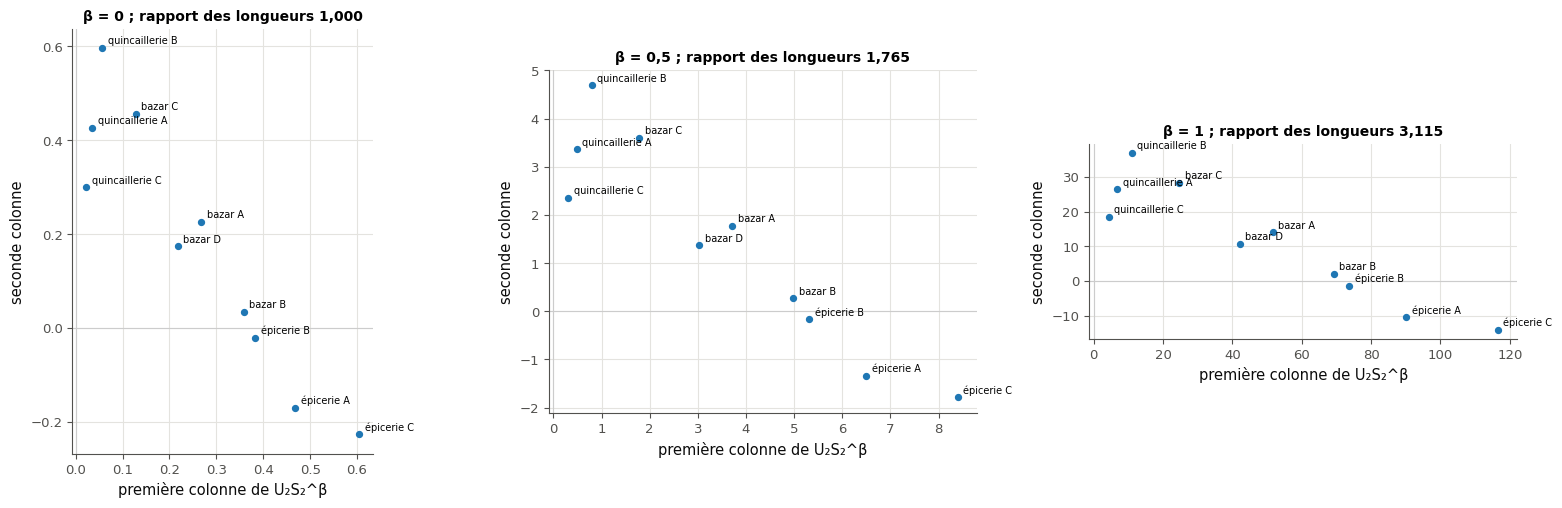

✅ Ex MB2.16 : tes facteurs et tes trois panneaux sont justes.


In [31]:
for letter, answer in zip("abcdef", [answer_MB2_16a, answer_MB2_16b, answer_MB2_16c, answer_MB2_16d, answer_MB2_16e, answer_MB2_16f]):
    check_answer(f"MB2.16{letter}", answer)

HIDDEN_C16 = {'table': [[18.0, 12, 3, 1], [22, 15, 5, 2], [4, 3, 16, 11], [2, 5, 21, 14], [12, 9, 10, 7], [9, 4, 13, 12]],
 'names': ['kiosque 1', 'kiosque 2', 'kiosque 3', 'kiosque 4', 'kiosque 5', 'kiosque 6'],
 'betas': [0.25, 0.6, 0.9],
 'beta': 0.4,
 'ids': ['MB2.16h', 'MB2.16i']}   # a hidden table, its names, three other betas, and the sub-IDs of the arrays expected


def factors_why_c16(axes, M, betas, names, arrays, sub_id):
    """What is wrong in a call of draw_factors_16 (French phrases): the arrays returned, then the three panels."""
    if not isinstance(arrays, (list, tuple)) or len(arrays) != len(betas):
        return [f"draw_factors_16 doit rendre la liste des {len(betas)} tableaux tracés, reçu {shown(arrays)}"]
    arrays = [as_floats(a) for a in arrays]
    shape = (len(M), 2)
    if any(a is None or a.shape != shape for a in arrays):
        return [f"chaque tableau tracé a une ligne par ligne de M et deux colonnes : la forme {shape}"]
    problems = []
    if not passes(sub_id, [a.tolist() for a in arrays]):
        flipped = any(passes(sub_id, [(a * signs).tolist() for a in arrays]) for signs in ([-1, 1], [1, -1], [-1, -1]))
        problems.append("au signe près d'une colonne : prends la SVD de mymath.svd_pca.svd, qui suit la convention de "
                        "signe de M12d" if flipped else
                        "les tableaux tracés ne sont pas U₂S₂^β pour les β reçus (dans l'ordre de betas), à partir de la "
                        "SVD de la table reçue")
    for k, (ax, beta, a) in enumerate(zip(axes, betas, arrays)):
        missing = []
        if not points_at(ax, a[:, 0], a[:, 1]):
            missing.append("un point par ligne, à ses deux coordonnées (ax.scatter, ou ax.plot avec un marqueur)")
        if not set(names) <= {text.get_text().strip() for text in ax.texts}:
            missing.append("le nom de chaque ligne près de son point (ax.annotate ou ax.text)")
        if ax.get_aspect() not in (1.0, "equal"):
            missing.append('la même échelle sur les deux axes (ax.set_aspect("equal"))')
        if not ax.get_xlabel() or not ax.get_ylabel():
            missing.append("des noms d'axes")
        if not gives(ax.get_title(), [float(np.linalg.norm(a[:, 0]) / np.linalg.norm(a[:, 1]))]):
            missing.append("en titre, le rapport des longueurs des deux colonnes (un nombre)")
        if missing:
            problems.append(f"panneau {k + 1} (β = {fr(beta, 2)}) : il manque " + " ; ".join(missing))
    return problems


with checked("MB2.16"):
    results_16 = []
    report_16 = reporter(results_16, stop=False)
    fig_16, axes_16 = plt.subplots(1, 3, figsize=(16, 5.2))
    try:
        result_16 = []
        opened_16 = drawn(lambda: result_16.append(draw_factors_16(axes_16, M_16, (0, 0.5, 1), SHOPS_16)))
        problems_16 = factors_why_c16(axes_16, M_16, (0, 0.5, 1), SHOPS_16, result_16[0], "MB2.16g")
        report_16(not problems_16, "draw_factors_16 (β = 0, ½ et 1) : les trois tableaux, les points, les noms, l'échelle, "
                  "les noms d'axes et les titres", "draw_factors_16 : " + " ; ".join(problems_16))
        fig_c16, axes_c16 = plt.subplots(1, 4)             # the 4th axes is the current one: plt.scatter would draw there
        try:
            hidden_c16 = []
            opened_16 += drawn(lambda: hidden_c16.append(draw_factors_16(axes_c16[:3], np.array(HIDDEN_C16["table"]),
                                                                          HIDDEN_C16["betas"], HIDDEN_C16["names"])))
            problems_c16 = factors_why_c16(axes_c16[:3], HIDDEN_C16["table"], HIDDEN_C16["betas"], HIDDEN_C16["names"],
                                           hidden_c16[0], HIDDEN_C16["ids"][0])
            elsewhere_16 = bool(axes_c16[3].lines or axes_c16[3].collections or axes_c16[3].texts or axes_c16[3].get_title())
        finally:
            plt.close(fig_c16)
        report_16(not problems_c16, "un appel caché de draw_factors_16 (une autre table, d'autres β) est juste aussi",
                  "un appel caché de draw_factors_16 (une autre table, d'autres β) : " + " ; ".join(problems_c16))
        rows_c16 = as_floats(factor_rows_16(np.array(HIDDEN_C16["table"]), HIDDEN_C16["beta"], k=3))
        shape_c16 = (len(HIDDEN_C16["table"]), 3)
        if rows_c16 is None or rows_c16.shape != shape_c16:
            why_c16 = (f"attendu U₃S₃^β, de forme {shape_c16} (k est le nombre de colonnes gardées), reçu "
                       f"{None if rows_c16 is None else rows_c16.shape}")
        elif passes(HIDDEN_C16["ids"][1], rows_c16.tolist()):
            why_c16 = ""
        elif any(passes(HIDDEN_C16["ids"][1], (rows_c16 * signs).tolist())
                 for signs in itertools.product([1, -1], repeat=3) if min(signs) < 0):
            why_c16 = "au signe près d'une colonne : prends la SVD de mymath.svd_pca.svd, qui suit la convention de signe de M12d"
        else:
            why_c16 = "ce n'est pas U₃S₃^β, les k = 3 premières colonnes de U multipliées par les puissances β de s"
        report_16(not why_c16, "factor_rows_16 sur la table cachée, avec k = 3 et un autre β, comme attendu",
                  f"factor_rows_16 sur la table cachée, avec k = 3 : {why_c16}")
        report_16(not opened_16 and not elsewhere_16, "tes fonctions dessinent dans les axes reçus",
                  "tes fonctions doivent dessiner dans les axes reçus (ax.scatter, ax.set_title…), sans ouvrir de figure ni "
                  "dessiner dans l'axe courant (plt.scatter, plt.title…)")
    except BaseException:
        plt.close(fig_16)
        raise
    fig_16.tight_layout()
    plt.show()
    verdict("MB2.16", all(results_16), "tes facteurs et tes trois panneaux sont justes.", "relis les lignes ❌ ci-dessus.")

**Ce qu'il faut observer** : quand $\beta$ monte, le nuage s'étire le long du premier axe, celui du profil moyen ; les magasins semblent alors plus proches les uns des autres ; $\beta = 1$ garde les angles de la table approchée, pas ceux de la table.

**Après la figure**, dans ta copie : quels magasins se rapprochent quand $\beta$ monte, et pourquoi ? Quel $\beta$ choisirais-tu pour comparer les magasins par le cosinus, et pour comparer les produits ?

💡 `factor_rows_16` : `U, s, Vt = mymath.svd_pca.svd(M)`, puis `U[:, :k] * s[:k] ** beta`. a) $(192{,}79 ;\ 61{,}90 ;\ 6{,}36)$ : la table est presque de rang 2. b) $(-0{,}264 ;\ -0{,}060 ;\ 0{,}132)$. c) $(0{,}822 ;\ 0{,}924 ;\ 0{,}973)$. d) $(1 ;\ 1{,}765 ;\ 3{,}115)$, soit $(s_1/s_2)^\beta$. e) Vrai. f) Faux : la troisième valeur singulière, petite mais non nulle, écarte un peu les cosinus de $\mathbf{M}$ de ceux de $\mathbf{M}_2$.

## Partie C · Déboguer, tester

Fiche §2, §4 et §7. Trois erreurs classiques, qui passent une vérification mal choisie ; un test de propriété de `pmi`. Les versions fausses et le code du collègue s'appuient sur la référence (`ref_cooc`, `ref_svd`), pour ne pas dépendre de ton code.

### Ex MB2.17 — Chasse à l'erreur : une PMI calculée sans le total, des facteurs U S^β et V S^β, une direction retirée sans diviser par u·u 🐛 ★ ⏱️ 30 min
**Objectif :** reconnaître trois erreurs classiques sur la PMI d'une table de comptes, la répartition des valeurs singulières et le retrait d'une direction, qui passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §2, §4 et §7 ; Ex MB2.2, MB2.4 et MB2.7 · **Parcours :** C, E

Un collègue a écrit trois fonctions, chacune accompagnée d'une vérification qui passe (cellule fournie) :
1. `pmi_from_counts(C)` doit rendre la table des PMI d'une table de **comptes** ; elle calcule `np.log(C / np.outer(C.sum(1), C.sum(0)))` sur les cases non nulles, et $-\infty$ ailleurs. Il l'a vérifiée sur une loi jointe : elle redonne `pmi`.
2. `split_factors(U, s, Vt, beta)` doit rendre les deux facteurs $\mathbf{U}\mathbf{S}^\beta$ et $\mathbf{V}\mathbf{S}^{1-\beta}$ d'une SVD compacte ; elle rend `U * s ** beta, Vt.T * s ** beta`. Il l'a vérifiée avec $\beta = \frac12$ sur les magasins de MB2.4 : le produit des deux facteurs redonne $\mathbf{M}$.
3. `remove_direction_bad(X, u)` doit retirer la direction $\mathbf{u}$ de chaque ligne de $\mathbf{X}$ ; elle rend `X - np.outer(X @ u, u)`. Il l'a vérifiée avec $\mathbf{u} = (0 ;\ 0{,}6 ;\ 0{,}8)$ sur les animaux de MB2.7 : elle redonne `remove_direction`.

À faire : trouve et corrige chaque erreur ; les fonctions corrigées s'appellent `pmi_from_counts_fixed`, `split_factors_fixed` et `remove_direction_fixed`, avec les mêmes arguments. Puis réponds :
- a) pour la table des comptes des oiseaux de MB2.2 (`BIRDS`), $\operatorname{PMI}(\text{forêt}, \text{pic})$ par `pmi_from_counts_fixed`, puis par `pmi_from_counts` (une liste de 2 nombres) ;
- b) pour les magasins de MB2.4 (`SHOPS`), avec $\beta = 1$ : la case (1, 1) (en haut à gauche) du produit des deux facteurs de `split_factors_fixed`, puis de `split_factors`, la SVD calculée par `mymath.svd_pca.svd` (une liste de 2 nombres) ;
- c) l'animal 1 de MB2.7 sans la direction $(1, 1, 1)$, par `remove_direction_fixed`, puis par `remove_direction_bad` (une liste de 6 nombres).

Dans ta copie : pour chacune des trois erreurs, pourquoi la vérification du collègue ne la voyait pas. La vérification essaie tes corrections sur des cas cachés : des tables de comptes de totaux variés, d'autres $\beta$ et d'autres matrices, des directions de normes diverses.

In [32]:
# The colleague's code
def pmi_from_counts(C):
    """The PMI table of a table of COUNTS C (-inf on the empty cells)."""
    C = np.asarray(C, dtype=float)
    out = np.full(C.shape, -np.inf)
    nonzero = C > 0
    out[nonzero] = np.log(C[nonzero] / np.outer(C.sum(axis=1), C.sum(axis=0))[nonzero])
    return out


def split_factors(U, s, Vt, beta):
    """The two factors U S^beta and V S^(1 - beta) of a compact SVD (U, s, Vt)."""
    return U * s ** beta, Vt.T * s ** beta


def remove_direction_bad(X, u):
    """X without the direction u: each row x becomes x minus its component along u."""
    X, u = np.asarray(X, dtype=float), np.asarray(u, dtype=float)
    return X - np.outer(X @ u, u)


# The colleague's checks: all pass
print("(1)", bool(np.allclose(pmi_from_counts(P), ref_cooc.pmi(P))), "(attendu True : sur une loi jointe)")
U_17, s_17, Vt_17 = ref_svd.svd(SHOPS)
A_17, B_17 = split_factors(U_17, s_17, Vt_17, 0.5)
print("(2)", bool(np.allclose(A_17 @ B_17.T, SHOPS)), "(attendu True : avec beta = 0.5)")
u_17 = np.array([0.0, 0.6, 0.8])
print("(3)", bool(np.allclose(remove_direction_bad(ANIMALS, u_17), ref_cooc.remove_direction(ANIMALS, u_17))),
      "(attendu True : avec u = (0 ; 0,6 ; 0,8))")

(1) True (attendu True : sur une loi jointe)
(2) True (attendu True : avec beta = 0.5)
(3) True (attendu True : avec u = (0 ; 0,6 ; 0,8))


In [33]:
def pmi_from_counts_fixed(C):
    """The PMI table of a table of COUNTS C (-inf on the empty cells)."""
    C = np.asarray(C, dtype=float)
    return mymath.cooccurrence.pmi(C / C.sum())          # the joint law: the counts divided by their total N


def split_factors_fixed(U, s, Vt, beta):
    """The two factors U S^beta and V S^(1 - beta) of a compact SVD (U, s, Vt)."""
    return U * s ** beta, Vt.T * s ** (1 - beta)          # the powers of S add up to 1


def remove_direction_fixed(X, u):
    """X without the direction u: each row x becomes x minus its component along u."""
    X, u = np.asarray(X, dtype=float), np.asarray(u, dtype=float)
    return X - np.outer(X @ u / (u @ u), u)               # divided by u·u: u need not be a unit vector


U_s17, s_s17, Vt_s17 = mymath.svd_pca.svd(SHOPS)
answer_MB2_17a = [float(pmi_from_counts_fixed(BIRDS)[0, 1]), float(pmi_from_counts(BIRDS)[0, 1])]
answer_MB2_17b = [float((lambda A, B: (A @ B.T)[0, 0])(*split_factors_fixed(U_s17, s_s17, Vt_s17, 1))),
                  float((lambda A, B: (A @ B.T)[0, 0])(*split_factors(U_s17, s_s17, Vt_s17, 1)))]
answer_MB2_17c = (np.ravel(remove_direction_fixed(ANIMALS[:1], np.ones(3))).tolist()
                  + np.ravel(remove_direction_bad(ANIMALS[:1], np.ones(3))).tolist())
print("a)", np.round(answer_MB2_17a, 4).tolist(), " b)", np.round(answer_MB2_17b, 4).tolist(),
      " c)", np.round(answer_MB2_17c, 4).tolist())

a) [0.6286, -3.9766]  b) [12.0, 20748.0]  c) [-1.0, 0.0, 1.0, -7.0, -6.0, -5.0]


In [34]:
counts_17r = np.array([[0.0, 6, 14, 20], [1, 2, 10, 22], [0, 0, 3, 22]])
N_17r = counts_17r.sum()
right_17r = math.log(counts_17r[0, 1] * N_17r / (counts_17r[0].sum() * counts_17r[:, 1].sum()))
wrong_17r = math.log(counts_17r[0, 1] / (counts_17r[0].sum() * counts_17r[:, 1].sum()))
wbm.record("MB2.17a", [right_17r, wrong_17r], decimals=6,
           mistakes={"pmi_from_counts_fixed oublie encore le total N : la loi jointe est la table des comptes divisée par N":
                         [wrong_17r, wrong_17r],
                     "le second nombre est celui de la version FAUSSE, pmi_from_counts": [right_17r, right_17r]})
shops_17r = np.array([[12.0, 96, 220], [78, 54, 5], [57, 114, 190], [132, 144, 140]])
U_17r, s_17r, Vt_17r = np.linalg.svd(shops_17r, full_matrices=False)
cell_17r = [float(np.sum(U_17r[0, :2] * s_17r[:2] ** (b + c) * Vt_17r[:2, 0])) for b, c in ((1, 0), (1, 1))]
wbm.record("MB2.17b", cell_17r, decimals=6,
           mistakes={"split_factors_fixed donne encore S^β aux deux facteurs : le second prend S^(1 − β)":
                         [cell_17r[1], cell_17r[1]],
                     "le second nombre est celui de la version FAUSSE, split_factors": [cell_17r[0], cell_17r[0]]})
x_17r, ones_17r = np.array([2.0, 3, 4]), np.ones(3)
fixed_17r = x_17r - (x_17r @ ones_17r) / (ones_17r @ ones_17r) * ones_17r
bad_17r = x_17r - (x_17r @ ones_17r) * ones_17r
wbm.record("MB2.17c", fixed_17r.tolist() + bad_17r.tolist(), decimals=6,
           mistakes={"remove_direction_fixed ne divise pas par u·u : avec (1, 1, 1), u·u = 3":
                         bad_17r.tolist() + bad_17r.tolist(),
                     "on divise par u·u, le carré de la norme, pas par la norme ‖u‖":
                         (x_17r - (x_17r @ ones_17r) / math.sqrt(3) * ones_17r).tolist() + bad_17r.tolist(),
                     "les trois derniers nombres sont ceux de la version FAUSSE, remove_direction_bad":
                         fixed_17r.tolist() + fixed_17r.tolist()})

WBM_ANSWER {"array_rounded": {"1": "010b1c48393d192a3d7a4d40dc543ed8a51128af503c7e0c43b12196de1168ed", "2": "455e08700eb510b16d11f7b751f37242af9210102bdf41e7ca11a0f7f2c0b2dc", "3": "8e75880209ef938343b73e67fc20d78c9450ea9d690077fdcb619242bb2352d7", "4": "b9e5077a5a5cd4866a8f1929e523e145448489b352dddf27990ffc4b68e78f6d", "5": "bbc13c5baa42120e5d70d99a1f56154486331c583d7b0fa1a85d03314797a6a1"}, "decimals": 6, "element_coarse": [["de81e45268b03bc418222ae62f658b369bace705f43d85a5b2bb89f60a529826"], ["d4c0ca736d05478a177e22cf6b976612ba4c0512b125fec5010c2e4b7fdfef1d"]], "element_coarse_any": [["5d35bd3919bc4950eaef7ba9855c1573a8722a385e885c893bf306dc1c80c381", "83c5b5fe09e636668da62bde0847474a3e77a0a0f54e4d572bb771ecfa00a60e", "7bc9f93891206f11ce1e83e0a9ed4f9b7be9db471c24796ad0ea7b87800dc05f", "da604795b4e908a2eb7511d9d13cf7945033cb5c4b072650858a7a98943aab43", "4a155a1bb7a3f24707af7a8da5f20761ea1ca424a7e50950027161caf3837937"], ["c0013a1e5698f839e3de700d72a5c0f336192e482b546802f35a040079083e

In [35]:
for letter, answer in zip("abc", [answer_MB2_17a, answer_MB2_17b, answer_MB2_17c]):
    check_answer(f"MB2.17{letter}", answer)

CASES_C17 = {'laws': [[[0.2, 0.05], [0.15, 0.6]], [[0.1, 0.0, 0.35], [0.2, 0.05, 0.3]]],
 'counts': [[[3, 0, 7], [12, 5, 0], [0, 9, 4]], [[30, 12], [0, 0], [7, 51], [22, 3]],
            [[260, 41, 7, 0, 19], [88, 300, 12, 5, 0]]],
 'factors': [{'M': [[4.0, 1, 7], [2, 9, 3], [8, 5, 1], [6, 2, 2], [1, 3, 9]], 'beta': 0.0},
             {'M': [[4.0, 1, 7], [2, 9, 3], [8, 5, 1], [6, 2, 2], [1, 3, 9]], 'beta': 0.3},
             {'M': [[2.0, 0, 5, 1, 3, 7], [6, 4, 1, 0, 2, 2], [1, 8, 3, 5, 0, 4], [3, 2, 2, 6, 9, 1]],
              'beta': 1.0}],
 'directions': [{'X': [[1.5, -2.5, 0.5], [3, 1, -1], [0, 2.5, 4], [-2, -1, 3]], 'u': [0.1, -0.2, 0.05]},
                {'X': [[3.0, 1], [-1, 4], [2, 2], [0, -3], [5, -2]], 'u': [3.5, -8.0]},
                {'X': [[1.0, 0, 2, -1], [3, 3, 0, 1], [-2, 1, 1, 4]], 'u': [1.5, -1, 0, 2.5]}]}   # the hidden cases of the three corrected functions
rng_c17 = np.random.default_rng()       # at each run: new factors for the counts

results_17, parts_17 = [], []


def report_17(ok, success, failure):
    results_17.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_17(part, name, function, *args, **kwargs):
    """function(*args, **kwargs); an error of the learner's code becomes one ❌ line that names the function (the check of
    this part stops there, the final verdict stays)."""
    try:
        return function(*args, **kwargs)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        report_17(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:160]}")
        parts_17.append(part)
        raise StopCheck from None


with checked("MB2.17"):                                       # (1) pmi_from_counts_fixed
    wrong_17 = []
    for law_c17 in CASES_C17["laws"]:                         # joint laws (sum 1): the PMI of pmi
        law_c17 = np.array(law_c17)
        got_c17 = as_floats(call_17(1, "pmi_from_counts_fixed", pmi_from_counts_fixed, law_c17.copy()))
        if got_c17 is None or got_c17.shape != law_c17.shape or not matches(got_c17, ref_cooc.pmi(law_c17)):
            wrong_17.append("sur une loi jointe (de somme 1), ta fonction doit redonner pmi")
    for counts_c17 in CASES_C17["counts"]:                    # tables of counts: k C describes the same law as C
        counts_c17 = np.array(counts_c17)
        before_c17 = counts_c17.copy()
        got_c17 = as_floats(call_17(1, "pmi_from_counts_fixed", pmi_from_counts_fixed, counts_c17))
        if got_c17 is None or got_c17.shape != counts_c17.shape:
            wrong_17.append(f"attendu une table de la forme des comptes, {counts_c17.shape}, reçu {shown(got_c17)[:60]}")
            continue
        if not np.array_equal(counts_c17, before_c17):
            wrong_17.append("ta fonction modifie la table reçue : travaille sur une copie")
            continue
        k_c17 = float(rng_c17.uniform(0.2, 50.0))
        scaled_c17 = as_floats(call_17(1, "pmi_from_counts_fixed", pmi_from_counts_fixed, k_c17 * counts_c17))
        if not matches(scaled_c17, got_c17, rtol=1e-9, atol=1e-9):
            wrong_17.append(f"une table de comptes de total {int(counts_c17.sum())} : multiplier tous les comptes par un "
                            "même nombre ne change pas la loi, donc pas la PMI ; ta fonction doit rendre la même table "
                            "pour C et pour k·C")
    report_17(not wrong_17, "(1) pmi_from_counts_fixed : des lois jointes, et trois tables de comptes de totaux variés, "
              "multipliées par un facteur tiré au hasard", "(1) pmi_from_counts_fixed : " + " ; ".join(list(dict.fromkeys(wrong_17))[:2]))
    parts_17.append(1)

with checked("MB2.17"):                                       # (2) split_factors_fixed
    wrong_17 = []
    for case_c17 in CASES_C17["factors"]:
        U_c17, s_c17, Vt_c17 = ref_svd.svd(np.array(case_c17["M"]))
        beta_c17 = case_c17["beta"]
        got_c17 = call_17(2, "split_factors_fixed", split_factors_fixed, U_c17, s_c17, Vt_c17, beta_c17)
        if not isinstance(got_c17, (tuple, list)) or len(got_c17) != 2:
            wrong_17.append(f"split_factors_fixed doit rendre les deux facteurs, reçu {shown(got_c17)[:60]}")
            continue
        A_c17, B_c17 = (as_floats(f) for f in got_c17)
        shape_A, shape_B = U_c17.shape, Vt_c17.T.shape
        if A_c17 is None or B_c17 is None or A_c17.shape != shape_A or B_c17.shape != shape_B:
            wrong_17.append(f"les deux facteurs ont les formes {shape_A} (une ligne par ligne de M) et {shape_B} (une "
                            "ligne par colonne de M)")
            continue
        if not matches(A_c17, split_factors(U_c17, s_c17, Vt_c17, beta_c17)[0]):
            wrong_17.append("le premier facteur U S^β était juste : ne le change pas")
            continue
        if not np.allclose(A_c17 @ B_c17.T, (U_c17 * s_c17) @ Vt_c17, rtol=1e-9, atol=1e-9 * float(s_c17.max())):
            wrong_17.append(f"avec β = {fr(beta_c17, 2)} et une autre matrice, le produit des deux facteurs doit redonner "
                            "U S Vᵀ : les puissances de S des deux facteurs s'ajoutent")
    report_17(not wrong_17, "(2) split_factors_fixed : d'autres matrices, avec β = 0, 0,3 et 1",
              "(2) split_factors_fixed : " + " ; ".join(list(dict.fromkeys(wrong_17))[:2]))
    parts_17.append(2)

with checked("MB2.17"):                                       # (3) remove_direction_fixed
    wrong_17 = []
    for case_c17 in CASES_C17["directions"]:
        X_c17, u_c17 = np.array(case_c17["X"]), np.array(case_c17["u"])
        before_c17 = X_c17.copy()
        R_c17 = as_floats(call_17(3, "remove_direction_fixed", remove_direction_fixed, X_c17, u_c17))
        size_c17 = float(np.abs(X_c17).max()) * float(np.linalg.norm(u_c17))
        if R_c17 is None or R_c17.shape != X_c17.shape:
            wrong_17.append(f"attendu un tableau de la forme de X, {X_c17.shape}, reçu {shown(R_c17)[:60]}")
        elif not np.array_equal(X_c17, before_c17):
            wrong_17.append("ta fonction modifie le tableau reçu : travaille sur une copie")
        elif not np.allclose(R_c17 @ u_c17, 0.0, atol=1e-9 * size_c17):
            wrong_17.append(f"avec une direction u de norme {fr(float(np.linalg.norm(u_c17)), 2)}, chaque ligne du résultat "
                            "doit être orthogonale à u : on retire (x·u / u·u) u")
        elif not np.allclose((X_c17 - R_c17) @ null_space(u_c17[None, :]), 0.0, atol=1e-9 * size_c17):
            wrong_17.append("on ne retire à chaque ligne qu'un multiple de u : ce qui est orthogonal à u ne change pas")
    report_17(not wrong_17, "(3) remove_direction_fixed : trois directions cachées, de normes diverses",
              "(3) remove_direction_fixed : " + " ; ".join(list(dict.fromkeys(wrong_17))[:2]))
    parts_17.append(3)

if len(set(parts_17)) == 3:
    verdict("MB2.17", all(results_17), "les trois fonctions corrigées passent tous les cas.", "relis les lignes ❌ ci-dessus.")

✅ Ex MB2.17a : Bravo !
✅ Ex MB2.17b : Exact !
✅ Ex MB2.17c : Bien joué !
✅ (1) pmi_from_counts_fixed : des lois jointes, et trois tables de comptes de totaux variés, multipliées par un facteur tiré au hasard
✅ (2) split_factors_fixed : d'autres matrices, avec β = 0, 0,3 et 1
✅ (3) remove_direction_fixed : trois directions cachées, de normes diverses
✅ Ex MB2.17 : les trois fonctions corrigées passent tous les cas.


**Après la vérification**, dans ta copie : pour chaque erreur, pourquoi la vérification du collègue ne la voyait-elle pas, et quelle vérification l'aurait vue ?

💡 (1) `pmi_from_counts` oublie le total $N$ : elle rend $\operatorname{PMI} - \ln N$, et $N = 1$ sur une loi jointe. Correction : `mymath.cooccurrence.pmi(C / C.sum())`. a) $0{,}629$, puis $0{,}629 - \ln 100 \approx -3{,}977$. (2) `split_factors` donne $\mathbf{S}^\beta$ aux deux facteurs : leur produit vaut $\mathbf{U}\mathbf{S}^{2\beta}\mathbf{V}^\top$, qui n'est $\mathbf{M}$ que pour $\beta = \frac12$. Correction : `Vt.T * s ** (1 - beta)`. b) 12 avec la correction, 20 748 avec l'erreur ($399^2 \times \frac47 \times \frac{6}{19} - 133^2 \times \frac47 \times \frac{15}{19}$). (3) `remove_direction_bad` ne divise pas par $\mathbf{u}\cdot\mathbf{u}$ : elle n'est juste que pour un $\mathbf{u}$ unitaire. Correction : `X - np.outer(X @ u / (u @ u), u)`. c) $(-1, 0, 1)$, puis $(-7, -6, -5)$.

### Ex MB2.18 — Un test de propriété de `pmi` sur des tables tirées au hasard : la borne, la transposition, et la moyenne qui redonne l'information mutuelle de M06 🛠️ ★ ⏱️ 35 min
**Objectif :** écrire les contrôles d'un test de propriété de la table des PMI, sur des lois tirées au hasard, et voir ce qu'il attrape et ce qu'il ne peut pas attraper.  
**Prérequis :** fiche §2 ; M06 ; Ex MB2.13 · **Parcours :** C

La cellule fournie donne la boucle du test, `pmi_property_test_18(n_trials, rng, func=None, rtol=1e-9, checks=None)` : quand `func` vaut `None`, elle prend `mymath.cooccurrence.pmi` **au moment de l'appel**, et, quand `checks` vaut `None`, ta fonction `failed_checks_18` ; pour chacun des `n_trials` essais, dans cet ordre, elle tire `m = int(rng.integers(1, 6))`, `n = int(rng.integers(1, 6))`, `W = rng.random((m, n)) ** 2`, puis, si `rng.random() < 0.4`, met à 0 les cases où `rng.random((m, n)) < 0.3` (des cases vides) ; si `W` est nulle, elle met `W[0, 0] = 1` ; elle divise `W` par sa somme, appelle `checks(P, f, rtol)`, où `P` est la loi tirée et `f` la fonction testée, et ajoute 1 au compteur de chaque nom rendu ; elle rend le dictionnaire des trois compteurs d'essais `"bound"`, `"transpose"` et `"mean"`.

Écris les contrôles, `failed_checks_18(P, func, rtol=1e-9)`, qui rend l'**ensemble** des noms des contrôles qui échouent pour la loi `P` (`set()` si tout passe) : avec `T = func(P)`,
- `"bound"` échoue si `T` n'a pas la forme de `P`, si une case de probabilité non nulle a une PMI non finie, ou si l'une d'elles dépasse $\min(-\ln p(x), -\ln p(y))$ de plus de $\texttt{rtol}\cdot\max(1, \lvert\text{borne}\rvert)$ ;
- `"transpose"`, si `func(P.T)` n'a pas la forme de `T.T`, n'a pas ses $-\infty$ aux mêmes places, ou s'en écarte ailleurs de plus de `rtol` (`np.allclose` avec `rtol` et `atol` égaux à `rtol`) ;
- `"mean"`, si $\sum p(x, y)\,T(x, y)$, sur les cases non vides, s'écarte de `mymath.info.mutual_information(P, base=math.e)` de plus de $\texttt{rtol}\cdot\max(1, \lvert\text{moyenne}\rvert)$ (ou n'est pas finie).

Une exception levée par `func` fait échouer les trois contrôles. La cellule fournie donne aussi quatre versions fausses de `pmi` : `decimal` (le logarithme en base 10), `conditional` ($\ln P(Y = y \mid X = x)$, sans diviser par $p(y)$), `zeros_to_zero` (0 au lieu de $-\infty$ sur les cases vides) et `lift` (le lift, sans le logarithme, 0 sur les cases vides). Puis :
- a) avec `rng = np.random.default_rng(7118)` et 300 essais, avec ta fonction `pmi` et tes contrôles : vrai ou faux, les trois compteurs sont nuls ;
- b) avec le même départ (un nouveau `default_rng(7118)` chaque fois, 300 essais) et chacune des quatre versions fausses, dans l'ordre `decimal`, `conditional`, `zeros_to_zero`, `lift` : les trois compteurs, dans l'ordre `"bound"`, `"transpose"`, `"mean"` (une liste de 4 listes de 3 entiers) ;
- c) dans ta copie : lesquelles passent le test, ou passent l'un des contrôles, et pourquoi c'est normal ; qu'est-ce qui, dans le dépôt, vérifie ce qu'elles ont de faux ?

La vérification lance aussi ton test sur deux départs cachés de 40 essais, avec la référence (compteurs nuls) et avec quatre versions fausses cachées, qui faussent chacune une ou deux des propriétés ; elle remplace aussi un instant `mymath.cooccurrence.pmi` par l'une d'elles, pour l'appel sans `func`. Ce qu'il faut retenir : ce test ajoute à ceux de `tests/test_mb2_cooccurrence.py` des tables de formes et de cases vides tirées au hasard ; chacun de ses contrôles attrape certaines erreurs et en laisse passer d'autres ; un test se juge aux erreurs qu'il attrape, et à celles qu'il ne peut pas attraper.

In [36]:
def decimal(P):
    """WRONG: the PMI in base 10."""
    return ref_cooc.pmi(P) / math.log(10)


def conditional(P):
    """WRONG: ln P(Y = y | X = x), without dividing by p(y); -inf on the empty cells."""
    P = np.asarray(P, dtype=float)
    out = np.full(P.shape, -np.inf)
    rows, cols = np.nonzero(P > 0)
    out[rows, cols] = np.log(P[rows, cols]) - np.log(P.sum(axis=1)[rows])
    return out


def zeros_to_zero(P):
    """WRONG: 0 instead of -inf on the empty cells."""
    T = ref_cooc.pmi(P)
    T[np.isneginf(T)] = 0.0
    return T


def lift(P):
    """WRONG: the lift p(x, y) / (p(x) p(y)), without the logarithm; 0 on the empty cells."""
    P = np.asarray(P, dtype=float)
    out = np.zeros(P.shape)
    rows, cols = np.nonzero(P > 0)
    out[rows, cols] = P[rows, cols] / (P.sum(axis=1)[rows] * P.sum(axis=0)[cols])
    return out


# The loop of the property test (provided): the draws, in a fixed order, and the counters
def pmi_property_test_18(n_trials, rng, func=None, rtol=1e-9, checks=None):
    """n_trials random joint laws, drawn in this order: m = int(rng.integers(1, 6)), n = int(rng.integers(1, 6)),
    W = rng.random((m, n)) ** 2, then, if rng.random() < 0.4, W set to 0 where rng.random((m, n)) < 0.3; W[0, 0] = 1 if W
    is zero; the law is W / W.sum(). func (the function tested) defaults to mymath.cooccurrence.pmi, checks to your
    failed_checks_18, both looked up at the call; each name returned by checks(law, func, rtol) adds 1 to its counter.
    Returns the counters "bound", "transpose", "mean"."""
    f = mymath.cooccurrence.pmi if func is None else func
    chk = failed_checks_18 if checks is None else checks
    counts = {"bound": 0, "transpose": 0, "mean": 0}
    for _ in range(n_trials):
        m = int(rng.integers(1, 6))
        n = int(rng.integers(1, 6))
        W = rng.random((m, n)) ** 2
        if rng.random() < 0.4:
            W[rng.random((m, n)) < 0.3] = 0.0
        if W.sum() == 0:
            W[0, 0] = 1.0
        for name in chk(W / W.sum(), f, rtol):
            if name not in counts:
                raise ValueError(f"les contrôles rendent {name!r} : les noms sont 'bound', 'transpose' et 'mean'")
            counts[name] += 1
    return counts

In [37]:
def failed_checks_18(P, func, rtol=1e-9):
    """The set of the names of the checks that fail for the joint law P, among "bound", "transpose" and "mean" (set() when
    all pass); func is the function tested."""
    P = np.asarray(P, dtype=float)
    try:
        T = np.asarray(func(P), dtype=float)
        TT = np.asarray(func(P.T), dtype=float)
    except Exception:  # noqa: BLE001 - an exception of the function tested fails the three checks
        return {"bound", "transpose", "mean"}
    failed = set()
    nonzero = P > 0
    if T.shape != P.shape:
        return {"bound", "transpose", "mean"}
    p_x, p_y = P.sum(axis=1), P.sum(axis=0)
    rows, cols = np.nonzero(nonzero)
    bound = np.minimum(-np.log(p_x[rows]), -np.log(p_y[cols]))
    values = T[rows, cols]
    if not np.all(np.isfinite(values)) or np.any(values > bound + rtol * np.maximum(1.0, np.abs(bound))):
        failed.add("bound")
    if (TT.shape != T.T.shape or not np.array_equal(np.isneginf(TT), np.isneginf(T.T))
            or not np.allclose(TT[~np.isneginf(TT)], T.T[~np.isneginf(T.T)], rtol=rtol, atol=rtol)):
        failed.add("transpose")
    mean = float(np.sum(P[nonzero] * T[nonzero]))
    if not math.isfinite(mean) or abs(mean - mymath.info.mutual_information(P, base=math.e)) > rtol * max(1.0, abs(mean)):
        failed.add("mean")
    return failed


KEYS_18 = ("bound", "transpose", "mean")
mine_18 = pmi_property_test_18(300, np.random.default_rng(7118))
answer_MB2_18a = all(mine_18[key] == 0 for key in KEYS_18)
with np.errstate(divide="ignore", invalid="ignore"):
    wrong_18 = {name: pmi_property_test_18(300, np.random.default_rng(7118), func=function)
                for name, function in (("decimal", decimal), ("conditional", conditional), ("zeros_to_zero", zeros_to_zero),
                                       ("lift", lift))}
answer_MB2_18b = [[counts[key] for key in KEYS_18] for counts in wrong_18.values()]
for name_18, counts_18 in {"ta pmi": mine_18, **wrong_18}.items():
    print(f"{name_18:14s}", counts_18)
print("a)", answer_MB2_18a, " b)", answer_MB2_18b)

ta pmi         {'bound': 0, 'transpose': 0, 'mean': 0}
decimal        {'bound': 0, 'transpose': 0, 'mean': 180}
conditional    {'bound': 0, 'transpose': 279, 'mean': 227}
zeros_to_zero  {'bound': 0, 'transpose': 0, 'mean': 0}
lift           {'bound': 300, 'transpose': 0, 'mean': 300}
a) True  b) [[0, 0, 180], [0, 279, 227], [0, 0, 0], [300, 0, 300]]


In [38]:
def counters_18r(seed, func, n_trials=300, bound_min=True, all_cells=False):
    """The loop and the checks of the statement written again (the oracle), with two classic variants: the bound with
    max instead of min, and the mean over all the cells (0 × −∞ gives nan)."""
    from scipy.special import xlogy
    rng, counts = np.random.default_rng(seed), [0, 0, 0]
    for _ in range(n_trials):
        m, n = int(rng.integers(1, 6)), int(rng.integers(1, 6))
        W = rng.random((m, n)) ** 2
        if rng.random() < 0.4:
            W[rng.random((m, n)) < 0.3] = 0.0
        if W.sum() == 0:
            W[0, 0] = 1.0
        law = W / W.sum()
        with np.errstate(divide="ignore", invalid="ignore"):
            T, TT = np.asarray(func(law), dtype=float), np.asarray(func(law.T), dtype=float)
            px, py = law.sum(axis=1), law.sum(axis=0)
            mi = float(np.sum(xlogy(law, law)) - np.sum(xlogy(px, px)) - np.sum(xlogy(py, py)))
            pick = np.minimum if bound_min else np.maximum
            failed = [False, False, False]
            for i in range(m):
                for j in range(n):
                    if law[i, j] > 0:
                        b = float(pick(-math.log(px[i]), -math.log(py[j])))
                        if not math.isfinite(T[i, j]) or T[i, j] > b + 1e-9 * max(1.0, abs(b)):
                            failed[0] = True
            same_places = np.array_equal(np.isneginf(TT), np.isneginf(T.T))
            failed[1] = not (same_places and np.allclose(TT[~np.isneginf(TT)], T.T[~np.isneginf(T.T)], rtol=1e-9, atol=1e-9))
            cells = np.ones_like(law, dtype=bool) if all_cells else law > 0
            mean = float(np.sum(law[cells] * T[cells]))
            failed[2] = not math.isfinite(mean) or abs(mean - mi) > 1e-9 * max(1.0, abs(mean))
        counts = [c + int(f) for c, f in zip(counts, failed)]
    return counts


def decimal(P):
    """WRONG: the PMI in base 10."""
    return ref_cooc.pmi(P) / math.log(10)


def conditional(P):
    """WRONG: ln P(Y = y | X = x), without dividing by p(y); -inf on the empty cells."""
    P = np.asarray(P, dtype=float)
    out = np.full(P.shape, -np.inf)
    rows, cols = np.nonzero(P > 0)
    out[rows, cols] = np.log(P[rows, cols]) - np.log(P.sum(axis=1)[rows])
    return out


def zeros_to_zero(P):
    """WRONG: 0 instead of -inf on the empty cells."""
    T = ref_cooc.pmi(P)
    T[np.isneginf(T)] = 0.0
    return T


def lift(P):
    """WRONG: the lift p(x, y) / (p(x) p(y)), without the logarithm; 0 on the empty cells."""
    P = np.asarray(P, dtype=float)
    out = np.zeros(P.shape)
    rows, cols = np.nonzero(P > 0)
    out[rows, cols] = P[rows, cols] / (P.sum(axis=1)[rows] * P.sum(axis=0)[cols])
    return out


versions_18r = [decimal, conditional, zeros_to_zero, lift]
wbm.record("MB2.18a", all(c == 0 for c in counters_18r(7118, ref_cooc.pmi)),
           mistakes={"avec une fonction juste, aucun compteur ne compte : un compteur non nul vient de tes contrôles "
                     "(leurs tolérances, ce qu'ils comparent) ou de ta pmi (relance ses tests)": False})
table_18r = [counters_18r(7118, f) for f in versions_18r]
wbm.record("MB2.18b", table_18r,
           mistakes={"la borne est le MINIMUM de −ln p(x) et −ln p(y)": [counters_18r(7118, f, bound_min=False)
                                                                       for f in versions_18r],
                     "la moyenne ne porte que sur les cases non vides (0 × −∞ n'est pas un nombre)":
                         [counters_18r(7118, f, all_cells=True) for f in versions_18r],
                     "l'ordre des versions : decimal, conditional, zeros_to_zero, lift": table_18r[::-1]})
PMI_C18 = ref_cooc.pmi                    # captured: the hidden versions never call a function replaced later


def half_c18(P):
    """WRONG: half the PMI (the mean is wrong; the bound and the transposition hold)."""
    return 0.5 * PMI_C18(P)


def double_c18(P):
    """WRONG: twice the PMI (the bound and the mean are wrong; the transposition holds)."""
    return 2.0 * PMI_C18(P)


def finite_tall_c18(P):
    """WRONG for a table with more rows than columns: -1e300 instead of -inf on the empty cells."""
    T = PMI_C18(P)
    if T.shape[0] > T.shape[1]:
        T[np.isneginf(T)] = -1e300
    return T


def tall_shift_c18(P):
    """WRONG for a table with more rows than columns: each finite PMI moved by 0.2 (i - mean of i under p(x)), which
    keeps the mean."""
    P = np.asarray(P, dtype=float)
    T = PMI_C18(P)
    if T.shape[0] > T.shape[1]:
        i = np.arange(T.shape[0], dtype=float)
        shift = 0.2 * (i - np.sum(P.sum(axis=1) * i))
        T = np.where(np.isfinite(T), T + shift[:, None], T)
    return T


for seed_18r, ids_18r in [(7141,
  {'half_c18': {'mean': 'MB2.18d'},
   'double_c18': {'bound': 'MB2.18e', 'mean': 'MB2.18f'},
   'finite_tall_c18': {'transpose': 'MB2.18g'},
   'tall_shift_c18': {'bound': 'MB2.18h', 'transpose': 'MB2.18i'}}),
 (7142,
  {'half_c18': {'mean': 'MB2.18j'},
   'double_c18': {'bound': 'MB2.18k', 'mean': 'MB2.18l'},
   'finite_tall_c18': {'transpose': 'MB2.18m'},
   'tall_shift_c18': {'bound': 'MB2.18n', 'transpose': 'MB2.18o'}})]:                    # the counters of the hidden versions, on the hidden starts
    for name_18r, by_key_18r in ids_18r.items():
        counts_18r = dict(zip(("bound", "transpose", "mean"), counters_18r(seed_18r, globals()[name_18r], n_trials=40)))
        for key_18r, sub_id_18r in by_key_18r.items():
            wbm.record(sub_id_18r, counts_18r[key_18r])

WBM_ANSWER {"hash": "701a7dfbab3a2c82e022ab8abd98b8d9fee5afd2b8b32f55d917e701b3419f9e", "id": "MB2.18a", "kind": "bool", "mistakes": {"4c9f72193f69d361db5d5db9a40b49c2610476033a04efaebfc9660dfcd31ff0": "avec une fonction juste, aucun compteur ne compte : un compteur non nul vient de tes contrôles (leurs tolérances, ce qu'ils comparent) ou de ta pmi (relance ses tests)"}}
📝 Ex MB2.18a : réponse enregistrée (bool).


WBM_ANSWER {"decimals": 0, "element_hashes": ["c1239dcb9238d79354ea94c722c0a50d2ee73f8de0616676dd462afabaadf5a3", "1b8ca563c866f158dff37fe55cefd519d939d3cea17d0bf68650ca36e2eb6fe9", "a00dcb614141b18ad7fe022cd2d1a70467def9bce6a449d3bf0b1e8ff2a01114", "f6e733e31fea9acc68742210ffb0e3226e4901102c7e446a50cce5e1d44c35c7", "287df5fc3d7e0fd4490182ebfcea18aa4a0e090f668796d3741ab372250260eb", "897faf641d4a22f484294b35ac51a65d00d201f80fce2f60460fc3bca9c303cc", "4d9d958c7b37123d40c813c7cc19a471fddcb710b523f0ad9443a15dbc01a993", "7fabf39d92e506074068e9160b168374e76906dc43523e62da5941ed7944ad78", "ec8dc817165a3732bac123cd869473f5272c2e2b6cf95669c024bf803941ec59", "bf312e6c3345b96de142b69795468d47c86d6dd5a4a8cf8633c6989f895cfde0", "544593bee8a1196e22193a9da74968d67373013850a5966ef97269f36da6d62f", "6977e5f3628f229f293777eb4749e31389efd2baea9ba0c508022c3d4b061744"], "hash": "549fd184bd7e7c59dd4e445a5ed9a9e1fe7d6f1f7242209eb8d34a84570404c1", "id": "MB2.18b", "integer": true, "kind": "array", "mistakes"

In [39]:
for letter, answer in zip("ab", [answer_MB2_18a, answer_MB2_18b]):
    check_answer(f"MB2.18{letter}", answer)

PMI_C18 = ref_cooc.pmi                    # captured: the hidden versions never call a function replaced later


def half_c18(P):
    """WRONG: half the PMI (the mean is wrong; the bound and the transposition hold)."""
    return 0.5 * PMI_C18(P)


def double_c18(P):
    """WRONG: twice the PMI (the bound and the mean are wrong; the transposition holds)."""
    return 2.0 * PMI_C18(P)


def finite_tall_c18(P):
    """WRONG for a table with more rows than columns: -1e300 instead of -inf on the empty cells."""
    T = PMI_C18(P)
    if T.shape[0] > T.shape[1]:
        T[np.isneginf(T)] = -1e300
    return T


def tall_shift_c18(P):
    """WRONG for a table with more rows than columns: each finite PMI moved by 0.2 (i - mean of i under p(x)), which
    keeps the mean."""
    P = np.asarray(P, dtype=float)
    T = PMI_C18(P)
    if T.shape[0] > T.shape[1]:
        i = np.arange(T.shape[0], dtype=float)
        shift = 0.2 * (i - np.sum(P.sum(axis=1) * i))
        T = np.where(np.isfinite(T), T + shift[:, None], T)
    return T


BROKEN_C18 = {"half_c18": ("mean",), "double_c18": ("bound", "mean"), "finite_tall_c18": ("transpose",),
              "tall_shift_c18": ("bound", "transpose")}           # the properties each hidden version can break
HIDDEN_C18 = [(7141,
  {'half_c18': {'mean': 'MB2.18d'},
   'double_c18': {'bound': 'MB2.18e', 'mean': 'MB2.18f'},
   'finite_tall_c18': {'transpose': 'MB2.18g'},
   'tall_shift_c18': {'bound': 'MB2.18h', 'transpose': 'MB2.18i'}}),
 (7142,
  {'half_c18': {'mean': 'MB2.18j'},
   'double_c18': {'bound': 'MB2.18k', 'mean': 'MB2.18l'},
   'finite_tall_c18': {'transpose': 'MB2.18m'},
   'tall_shift_c18': {'bound': 'MB2.18n', 'transpose': 'MB2.18o'}})]   # two hidden starts, and the sub-IDs of the counters expected for each version

with checked("MB2.18"):
    results_18 = []
    report_18 = reporter(results_18, stop=False)
    N_C18 = 40
    PROPERTIES_C18 = {"bound": "la borne min(−ln p(x), −ln p(y)) sur les cases non vides",
                      "transpose": "que func(P.T) redonne la transposée (−∞ aux mêmes places, le reste à rtol près)",
                      "mean": "que la moyenne des PMI sous P redonne l'information mutuelle de M06, en nats"}

    def run_c18(label, seed, **kwargs):
        """The loop of the notebook with your failed_checks_18, on a hidden start: its counters."""
        try:
            return pmi_property_test_18(N_C18, np.random.default_rng(seed), checks=failed_checks_18, **kwargs)
        except (NotImplementedError, MymathMissingError):
            raise
        except Exception as exc:  # noqa: BLE001 - the learner's error
            hint = (" ; failed_checks_18 doit rendre un ensemble de noms (set() si tout passe) : as-tu oublié le return ?"
                    if isinstance(exc, TypeError) and "NoneType" in str(exc) else "")
            print(f"❌ Ex MB2.18 : failed_checks_18 ({label}) lève {type(exc).__name__} : {str(exc)[:200]}{hint}")
            raise StopCheck from None

    def compare_c18(label, got, version, ids):
        """One ✅ when the three counters are those expected; else one ❌ per counter, naming the property."""
        wrong = []
        for key in ("bound", "transpose", "mean"):
            if version is None or key not in BROKEN_C18[version]:            # 0 by construction
                if got[key] != 0:
                    wrong.append((key, f"vaut {got[key]}, attendu 0 : "
                                       + ("avec une fonction juste, aucun contrôle ne compte : ton contrôle compte trop "
                                          "(sa tolérance rtol·max(1, |…|), ce qu'il compare)" if version is None else
                                          "cette version ne fausse pas cette propriété : ton contrôle compte trop (sa "
                                          "tolérance rtol·max(1, |…|), ce qu'il compare)")))
            elif not passes(ids[key], got[key]):
                wrong.append((key, ("vaut 0 : tes contrôles ne vérifient pas " + PROPERTIES_C18[key]
                                    + ", sur la fonction reçue (func, pas celle de mymath)") if got[key] == 0 else
                                   (f"vaut {got[key]}, ce n'est pas le compte attendu : relis ce que ce contrôle compare, "
                                    "et sur quelles cases")))
        if not wrong:
            report_18(True, f"{label} : les trois compteurs comme attendu", "")
        for key, why in wrong:
            report_18(False, "", f"{label} : le compteur {key!r} {why}")

    for start_c18, (seed_c18, ids_c18) in enumerate(HIDDEN_C18, start=1):
        compare_c18(f"la référence, départ caché {start_c18}", run_c18("la référence", seed_c18, func=ref_cooc.pmi),
                    None, {})
        for number_c18, name_c18 in enumerate(BROKEN_C18, start=1):
            label_c18 = f"une version fausse cachée n° {number_c18}, départ caché {start_c18}"
            compare_c18(label_c18, run_c18(label_c18, seed_c18, func=globals()[name_c18]), name_c18, ids_c18[name_c18])
    learner_pmi_c18 = mymath.cooccurrence.pmi                # replaced an instant, put back even if the check fails
    try:
        mymath.cooccurrence.pmi = half_c18
        got_c18 = run_c18("func=None", HIDDEN_C18[0][0])
    finally:
        mymath.cooccurrence.pmi = learner_pmi_c18
    compare_c18("la version fausse n° 1 mise un instant à la place de mymath.cooccurrence.pmi, sans func", got_c18,
                "half_c18", HIDDEN_C18[0][1]["half_c18"])
    verdict("MB2.18", all(results_18), "tes contrôles comptent juste sur la référence et sur les versions fausses "
            "cachées.", "relis les lignes ❌ ci-dessus.")

✅ Ex MB2.18a : Exact !
✅ Ex MB2.18b : Bien joué !
✅ la référence, départ caché 1 : les trois compteurs comme attendu
✅ une version fausse cachée n° 1, départ caché 1 : les trois compteurs comme attendu
✅ une version fausse cachée n° 2, départ caché 1 : les trois compteurs comme attendu
✅ une version fausse cachée n° 3, départ caché 1 : les trois compteurs comme attendu
✅ une version fausse cachée n° 4, départ caché 1 : les trois compteurs comme attendu
✅ la référence, départ caché 2 : les trois compteurs comme attendu
✅ une version fausse cachée n° 1, départ caché 2 : les trois compteurs comme attendu
✅ une version fausse cachée n° 2, départ caché 2 : les trois compteurs comme attendu
✅ une version fausse cachée n° 3, départ caché 2 : les trois compteurs comme attendu
✅ une version fausse cachée n° 4, départ caché 2 : les trois compteurs comme attendu
✅ la version fausse n° 1 mise un instant à la place de mymath.cooccurrence.pmi, sans func : les trois compteurs comme attendu
✅ Ex MB2.1

**Après la vérification**, dans ta copie : quel contrôle faudrait-il ajouter pour attraper `zeros_to_zero`, et pourquoi ne s'agit-il plus d'une propriété des seules cases non vides ?

💡 `failed_checks_18` appelle `func(P)` et `func(P.T)` dans un `try`, puis fait les trois contrôles sur les cases non vides. a) Vrai. c) `zeros_to_zero` passe tout : les trois contrôles ne regardent que les cases non vides, et ce sont les tests de `tests/test_mb2_cooccurrence.py` qui vérifient $-\infty$ sur les cases vides. `decimal` et `lift` passent la transposition (une table juste multipliée par un nombre, ou transformée case par case, se transpose comme elle). `decimal` passe aussi la borne : diviser une PMI par $\ln 10 > 1$ la rapproche de 0, et la borne $\min(-\ln p(x), -\ln p(y))$ est positive ou nulle ; elle n'échoue qu'au contrôle de la moyenne, et seulement quand l'information mutuelle n'est pas nulle (elle l'est pour une table d'une ligne ou d'une colonne). `conditional` passe la borne ($\ln P(y \mid x) \le 0$, sous toute borne positive).

## Partie D · Défi

Fiche §2 et §3. Les cases les plus associées d'une table cachée, retrouvées à partir de comptes, sur la table du notebook et trois tables cachées.

### Ex MB2.19 — Défi : retrouver, sur 3 000 observations, les cinq paires les plus associées d'une table cachée de 10 × 10, sans se laisser piéger par les cases rares 🏆 ★★★ ⏱️ 45 min
**Objectif :** retrouver les cases de plus grande PMI d'une table cachée à partir de comptes, en se protégeant des cases rares, et le vérifier sur des tables cachées.  
**Prérequis :** fiche §2 et §3 ; M04 ; Ex MB2.13 et MB2.15 · **Parcours :** C

Une table jointe cachée de $10 \times 10$ décrit, pour les articles vendus par un hypermarché, le rayon de l'article (10 rayons, en lignes) et la tranche horaire de la vente (10 tranches, en colonnes) ; quelques rayons et quelques tranches sont rares. Les « cinq paires les plus associées » sont les cinq cases de plus grande PMI de la table cachée, toutes de probabilité nettement non nulle. La cellule fournie donne `COUNTS_19`, les comptes, de forme $(10, 10)$, de 3 000 ventes tirées selon une telle table, et `pairs_found_19(pairs)`, qui compte combien des 5 paires `(ligne, colonne)` données sont parmi les cinq paires cachées, sans rien montrer d'elles.

Écris `top_pairs_19(counts)`, qui reçoit une table de comptes de 3 000 observations et rend une liste de 5 paires `(ligne, colonne)`, numérotées à partir de 0. Tout NumPy et SciPy sont permis, et ta `pmi`.

**Critère de réussite :** au moins 4 des 5 paires trouvées pour la table du notebook, et pour chacune de trois tables cachées de la vérification, dont les lignes et les colonnes sont renumérotées à chaque exécution, et dont les 3 000 ventes sont tirées à nouveau, en moins de 10 secondes en tout. La vérification recalcule aussi ta réponse a) avec ta fonction, et refuse une fonction qui rend les mêmes paires pour deux tables. Relève :
- a) le nombre de paires que ta méthode trouve pour la table du notebook, `pairs_found_19(top_pairs_19(COUNTS_19))` (un entier) ;
- b) le nombre de paires que trouve l'estimation directe, les cinq plus grandes valeurs de `pmi(COUNTS_19 / 3000)` (un entier) ;
- c) les comptes des cinq cases que choisit l'estimation directe, par PMI estimée décroissante (une liste de 5 entiers).

Point de départ : regarde les cases que choisit l'estimation directe, et leurs comptes ; la fiche (§2 et §3) et M04 (les pseudo-comptes) donnent des idées, et la méthode est libre.

In [40]:
COUNTS_19 = np.array([[47, 3, 47, 81, 166, 40, 25, 0, 2, 56], [24, 1, 35, 72, 37, 33, 29, 0, 3, 203],
 [41, 5, 37, 70, 90, 62, 168, 1, 1, 103], [3, 0, 1, 3, 1, 1, 1, 0, 0, 2], [2, 0, 1, 2, 0, 1, 1, 0, 0, 3],
 [26, 1, 43, 64, 46, 119, 29, 2, 2, 83], [42, 2, 35, 72, 59, 39, 28, 0, 2, 80],
 [26, 1, 146, 46, 34, 33, 20, 3, 1, 45], [2, 0, 0, 5, 0, 2, 0, 0, 0, 5], [34, 2, 47, 92, 37, 38, 38, 0, 1, 64]])   # 3 000 sales: rows the 10 departments, columns the 10 time slots


def pairs_found_19(pairs):
    """The number of the 5 pairs (row, column) given that are among the five most associated pairs of the hidden table
    of COUNTS_19: each pair is compared with the hidden answer by wbm.check, which shows nothing of it."""
    pairs = [tuple(int(v) for v in pair) for pair in pairs]
    if len(pairs) != 5 or len(set(pairs)) != 5 or not all(0 <= i < 10 and 0 <= j < 10 for i, j in pairs):
        raise ValueError(f"pairs_found_19 attend 5 paires (ligne, colonne) distinctes, de 0 à 9, reçu {pairs}")
    return sum(any(passes(f"MB2.19{letter}", list(pair)) for letter in "klmno") for pair in pairs)

In [41]:
J_19r = np.array([[0.012748834738, 0.000954600299, 0.015711517214, 0.027355069832, 0.056992276724, 0.01282391272, 0.011945675627,
  0.000494690453, 0.000583904696, 0.022883585144],
 [0.008319839389, 0.000750565825, 0.011861807919, 0.025607450877, 0.012759276085, 0.010096519971,
  0.009269780008, 0.000388956245, 0.000459102003, 0.065697970657],
 [0.015150704282, 0.001148949391, 0.014785739411, 0.0284939138, 0.027147033203, 0.016778114723, 0.049781646559,
  0.000595405527, 0.000702783086, 0.033127539094],
 [0.000299830219, 2.1225899e-05, 0.000353041096, 0.00057318212, 0.00037560515, 0.000315254188, 0.000269698407,
  1.0999629e-05, 1.2983342e-05, 0.000591558568],
 [0.000362192606, 2.5640723e-05, 0.000426470938, 0.000692399608, 0.000453728143, 0.000380824642, 0.000325793609,
  1.3287468e-05, 1.5683777e-05, 0.000714598215],
 [0.009868168646, 0.000810727915, 0.014214425084, 0.022648348796, 0.015265187837, 0.042959242033,
  0.010175486794, 0.000420133285, 0.000495901622, 0.025216913155],
 [0.011931632521, 0.000859585868, 0.012296672285, 0.024058977128, 0.016221431969, 0.01305529208, 0.009704864157,
  0.000445452325, 0.000525786788, 0.03168264134],
 [0.009716999405, 0.000680760915, 0.041747567197, 0.016908350178, 0.015014743585, 0.009312678584,
  0.009563393626, 0.000352782128, 0.000416404117, 0.014055229137],
 [0.000509904437, 3.6097695e-05, 0.000600397191, 0.000974778684, 0.000638770613, 0.000536135116, 0.000458660955,
  1.8706453e-05, 2.2080041e-05, 0.001006030478],
 [0.010893740625, 0.000805668063, 0.015738922398, 0.023064571913, 0.014339705487, 0.013817523051,
  0.011249742712, 0.000417511182, 0.000492806639, 0.022101301922]])                                  # the hidden joint law of COUNTS_19
counts_19r = np.array([[47, 3, 47, 81, 166, 40, 25, 0, 2, 56], [24, 1, 35, 72, 37, 33, 29, 0, 3, 203],
 [41, 5, 37, 70, 90, 62, 168, 1, 1, 103], [3, 0, 1, 3, 1, 1, 1, 0, 0, 2], [2, 0, 1, 2, 0, 1, 1, 0, 0, 3],
 [26, 1, 43, 64, 46, 119, 29, 2, 2, 83], [42, 2, 35, 72, 59, 39, 28, 0, 2, 80],
 [26, 1, 146, 46, 34, 33, 20, 3, 1, 45], [2, 0, 0, 5, 0, 2, 0, 0, 0, 5], [34, 2, 47, 92, 37, 38, 38, 0, 1, 64]])


def pmi_19r(J):
    with np.errstate(divide="ignore"):
        return np.log(J) - np.log(np.outer(J.sum(axis=1), J.sum(axis=0)))


def top5_19r(T):
    flat = sorted(((float(T[i, j]), i, j) for i in range(10) for j in range(10) if np.isfinite(T[i, j])), reverse=True)
    return [(i, j) for _, i, j in flat[:5]]


for letter_19r, pair_19r in zip("klmno", sorted(top5_19r(pmi_19r(J_19r)))):   # the five hidden pairs
    wbm.record(f"MB2.19{letter_19r}", list(pair_19r), decimals=0)
direct_19r = top5_19r(pmi_19r(counts_19r / counts_19r.sum()))
truth_19r = set(top5_19r(pmi_19r(J_19r)))
wbm.record("MB2.19b", len(set(direct_19r) & truth_19r),
           mistakes={"b) compte les paires de l'estimation directe qui sont parmi les cinq paires cachées, par "
                     "pairs_found_19": 5 - len(set(direct_19r) & truth_19r)})
wbm.record("MB2.19c", [int(counts_19r[i, j]) for i, j in direct_19r],
           mistakes={"par PMI estimée DÉCROISSANTE": [int(counts_19r[i, j]) for i, j in direct_19r[::-1]],
                     "les comptes des cinq cases de plus grande PMI estimée, pas les cinq plus grands comptes":
                         sorted((int(c) for c in counts_19r.ravel()), reverse=True)[:5]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["411ea64490cfd09aac0d867133a0712c9c5f0d671059d6b6722fdaeaeef82f81", "1912c128e580052dcb548f068feccc9135a11949a55a2b47f31e991f44b4beff"], "hash": "3c0c6e6408fb8e37cb0a1f6ae11ee55a0fcd1c31f1c9c638b830866f53f7fffc", "id": "MB2.19k", "integer": true, "kind": "array", "shape": [2]}
📝 Ex MB2.19k : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["7311b923eb1850278e176cc211a7a0c4acac109de1e5f2446f1cce03e2722e5c", "5c9227c831d566cd54ba7df7a0bcf3900a5fd3f61f1c3228e5512d999d5d64a2"], "hash": "b432b089438dd6db9c857f565c200e248495631f89e554737b8ec0fd2ff13019", "id": "MB2.19l", "integer": true, "kind": "array", "shape": [2]}
📝 Ex MB2.19l : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["7b96c5b9fb5a549537df0a7434d038dc518c5e6c0eaecef3a863a29e54ea6e05", "ca732b79d6300d35334a463981604f6938bd64a5149376c70181c6236a176157"], "hash": "0e5f8528e5f6b7b549afcbfab64d795fbb86e6964098f140

In [42]:
def top_pairs_19(counts, kappa=5.0):
    """The 5 most associated pairs (row, column), numbered from 0, of the hidden joint law whose counts (3 000
    observations, a (10, 10) array) are given: a list of 5 pairs."""
    counts = np.asarray(counts, dtype=float)
    expected = np.outer(counts.sum(axis=1), counts.sum(axis=0)) / counts.sum()     # the counts if independent
    score = np.log((counts + kappa) / (expected + kappa))                          # pseudo-counts towards independence
    best = np.argsort(-score, axis=None, kind="stable")[:5]
    return [(int(i), int(j)) for i, j in zip(*np.unravel_index(best, counts.shape))]


start_19 = time.perf_counter()
answer_MB2_19a = pairs_found_19(top_pairs_19(COUNTS_19))
print(f"a) {answer_MB2_19a} paires sur 5, en {time.perf_counter() - start_19:.4f} s")
direct_19 = mymath.cooccurrence.pmi(COUNTS_19 / COUNTS_19.sum())
order_19 = np.argsort(-direct_19, axis=None, kind="stable")[:5]
direct_pairs_19 = [(int(i), int(j)) for i, j in zip(*np.unravel_index(order_19, direct_19.shape))]
answer_MB2_19b = pairs_found_19(direct_pairs_19)
answer_MB2_19c = [int(COUNTS_19[i, j]) for i, j in direct_pairs_19]
print("b)", answer_MB2_19b, " c)", answer_MB2_19c, " ; cases choisies :", direct_pairs_19)

a) 5 paires sur 5, en 0.0038 s
b) 2  c) [3, 146, 3, 168, 2]  ; cases choisies : [(7, 7), (7, 2), (3, 0), (2, 6), (4, 0)]


In [43]:
for letter, answer in zip("bc", [answer_MB2_19b, answer_MB2_19c]):
    check_answer(f"MB2.19{letter}", answer)

HIDDEN_C19 = [[[0.02343933, 0.01776726, 0.0228772, 0.05477653, 0.01360586, 0.01498585, 0.00040789, 0.01483155, 0.00049256,
   0.00062896],
  [0.01440803, 0.01901452, 0.03220812, 0.01497376, 0.01392315, 0.01932932, 0.00041711, 0.01529879, 0.00050369,
   0.00064318],
  [0.00059462, 0.00075755, 0.00078267, 0.0005578, 0.00046913, 0.0006475, 1.368e-05, 0.00046225, 1.652e-05,
   2.11e-05],
  [0.01356559, 0.09767129, 0.01753175, 0.01758726, 0.0111437, 0.02255479, 0.0004137, 0.01424636, 0.00049957,
   0.00063792],
  [0.00064218, 0.00081814, 0.00084527, 0.00060242, 0.00050665, 0.00069928, 1.478e-05, 0.00049922, 1.784e-05,
   2.278e-05],
  [0.0150216, 0.01490329, 0.01608453, 0.01263663, 0.01188289, 0.01460993, 0.00033943, 0.04148274, 0.00040988,
   0.00052339],
  [0.01584827, 0.01742887, 0.02530427, 0.01442376, 0.01334482, 0.01719263, 0.0003277, 0.00910711, 0.00039572,
   0.00050531],
  [0.00908397, 0.01351107, 0.01693685, 0.01047774, 0.00788608, 0.04514483, 0.00021955, 0.00630005, 0.00026512,
   0.00033854],
  [0.00047156, 0.00060077, 0.00062069, 0.00044236, 0.00037204, 0.00051349, 1.085e-05, 0.00036658, 1.31e-05,
   1.673e-05],
  [0.01304767, 0.01597846, 0.06391543, 0.01584881, 0.00946869, 0.01586601, 0.00030996, 0.00997196, 0.0003743,
   0.00047796]],
 [[0.00064319, 0.01338623, 0.01695378, 0.00071785, 0.00079079, 0.01733166, 0.01369635, 0.01668881, 0.00991749,
   0.06421865],
  [1.646e-05, 0.00028877, 0.00038684, 1.837e-05, 2.023e-05, 0.0003387, 0.00044237, 0.00036091, 0.00027088,
   0.00041618],
  [0.00086238, 0.06233041, 0.0211701, 0.00096248, 0.00106027, 0.01536952, 0.02513404, 0.0148745, 0.01236335,
   0.01615674],
  [0.00072287, 0.01213269, 0.01668553, 0.00080678, 0.00088875, 0.01132603, 0.01863753, 0.01662402, 0.00968591,
   0.01834994],
  [2.68e-05, 0.00047028, 0.00063002, 2.991e-05, 3.295e-05, 0.0005516, 0.00072044, 0.00058777, 0.00044115,
   0.00067779],
  [0.00077421, 0.01392699, 0.01783676, 0.00086407, 0.00095187, 0.04795799, 0.02261106, 0.02023693, 0.01235107,
   0.01930699],
  [0.00043201, 0.00597454, 0.03802201, 0.00048215, 0.00053114, 0.0078489, 0.0115857, 0.00982057, 0.00731358,
   0.00947406],
  [0.00065461, 0.01215226, 0.01321376, 0.0007306, 0.00080483, 0.01226573, 0.0185578, 0.01615649, 0.01125924,
   0.0174221],
  [1.917e-05, 0.00033643, 0.00045069, 2.14e-05, 2.357e-05, 0.0003946, 0.00051538, 0.00042047, 0.00031559,
   0.00048486],
  [0.00093845, 0.01820035, 0.02370216, 0.00104738, 0.0011538, 0.02228162, 0.07616099, 0.02503501, 0.01652275,
   0.02323831]],
 [[0.00058732, 0.01865951, 0.02232591, 0.00707999, 0.01525546, 0.01014261, 0.02022667, 0.00071094, 0.00054382,
   0.00988399],
  [0.00079501, 0.02189883, 0.02918546, 0.01190725, 0.02464096, 0.01228646, 0.02162368, 0.00096234, 0.00073612,
   0.01515247],
  [2.531e-05, 0.00084708, 0.00084894, 0.00040188, 0.00086076, 0.00041184, 0.00075132, 3.064e-05, 2.344e-05,
   0.00043331],
  [0.0005697, 0.02402862, 0.02024349, 0.00815993, 0.01537879, 0.00809292, 0.01797852, 0.00068961, 0.0005275,
   0.03876904],
  [0.0005909, 0.06804847, 0.01932988, 0.00948275, 0.02210195, 0.01042497, 0.01958738, 0.00071527, 0.00054713,
   0.01059325],
  [0.00038353, 0.01580499, 0.0122359, 0.00682861, 0.01330092, 0.0063181, 0.03999663, 0.00046425, 0.00035512,
   0.00656056],
  [0.00056786, 0.0168785, 0.01410871, 0.03798479, 0.02402863, 0.00743725, 0.01419957, 0.00068739, 0.0005258,
   0.01138761],
  [3.585e-05, 0.00119954, 0.00120217, 0.00056909, 0.0012189, 0.0005832, 0.00106394, 4.339e-05, 3.319e-05,
   0.0006136],
  [2.145e-05, 0.00071776, 0.00071933, 0.00034052, 0.00072934, 0.00034896, 0.00063662, 2.596e-05, 1.986e-05,
   0.00036716],
  [0.00080665, 0.02496144, 0.09125263, 0.01163313, 0.03056664, 0.01194224, 0.02833058, 0.00097644, 0.00074691,
   0.0131394]]]   # three hidden joint laws of 10 × 10 (rows and columns renumbered at each run)
rng_c19 = np.random.default_rng()       # at each run: a new numbering of the rows and columns, and new sales


def pairs_why_c19(pairs):
    """'' when pairs is a list of 5 distinct pairs (row, column) of integers from 0 to 9, else the reason."""
    try:
        pairs = [tuple(int(v) for v in pair) for pair in pairs]
    except (TypeError, ValueError):
        return f"top_pairs_19 doit rendre une liste de 5 paires (ligne, colonne), reçu {shown(pairs)}"
    if len(pairs) != 5 or any(len(p) != 2 for p in pairs) or len(set(pairs)) != 5:
        return f"top_pairs_19 doit rendre 5 paires (ligne, colonne) distinctes, reçu {shown(pairs)}"
    if not all(0 <= v < 10 for p in pairs for v in p):
        return "les lignes et les colonnes se numérotent de 0 à 9"
    return ""


def top5_c19(law):
    """The five cells of largest PMI of a hidden joint law (the truth of a hidden table, not a method)."""
    T = ref_cooc.pmi(law)
    return {(int(i), int(j)) for i, j in zip(*np.unravel_index(np.argsort(-T, axis=None, kind="stable")[:5], T.shape))}


def rare_hint_c19(counts, pairs):
    """A hint when the pairs chosen hold cells of few sales (their PMI is very dispersed, MB2.15)."""
    few = [int(counts[i, j]) for i, j in pairs if counts[i, j] <= 5]
    return (f" ; {len(few)} des cases choisies n'ont que {', '.join(map(str, sorted(few)))} vente(s) : leur PMI estimée "
            "est très dispersée (MB2.15)") if few else ""


with checked("MB2.19"):
    results_19 = []
    report_19 = reporter(results_19, stop=False)
    elapsed_19 = 0.0
    start_19 = time.perf_counter()
    mine_19 = top_pairs_19(COUNTS_19.copy())
    elapsed_19 += time.perf_counter() - start_19
    why_19 = pairs_why_c19(mine_19)
    found_19 = pairs_found_19(mine_19) if not why_19 else 0
    report_19(not why_19 and found_19 >= 4, f"la table du notebook : {found_19} paires sur 5",
              f"la table du notebook : {why_19 or f'{found_19} paires sur 5, il en faut au moins 4'}"
              + ("" if why_19 else rare_hint_c19(COUNTS_19, mine_19)))
    if not filled(answer_MB2_19a):
        print("⏳ Ex MB2.19a : pas encore fait.")
    elif not why_19:
        report_19(answer_MB2_19a == found_19, "Ex MB2.19a : ta réponse est le score de ta fonction",
                  "Ex MB2.19a : ta réponse n'est pas le score que rend ta fonction maintenant, "
                  "pairs_found_19(top_pairs_19(COUNTS_19)) : exécute à nouveau ta cellule")
    answers_c19 = [sorted(map(tuple, np.asarray(mine_19, dtype=int).tolist())) if not why_19 else None]
    for k_c19, law_c19 in enumerate(HIDDEN_C19, start=1):
        rows_c19, cols_c19 = rng_c19.permutation(10), rng_c19.permutation(10)
        law_c19 = np.array(law_c19)[np.ix_(rows_c19, cols_c19)]
        law_c19 = law_c19 / law_c19.sum()                   # written to 8 decimals: summed to 1 again
        counts_c19 = rng_c19.multinomial(3000, law_c19.ravel()).reshape(10, 10)
        start_19 = time.perf_counter()
        got_c19 = top_pairs_19(counts_c19.copy())
        elapsed_19 += time.perf_counter() - start_19
        why_c19 = pairs_why_c19(got_c19)
        if not why_c19 and sorted(map(tuple, np.asarray(got_c19, dtype=int).tolist())) in answers_c19:
            why_c19 = ("ta fonction rend les mêmes paires pour deux tables différentes : elle doit les calculer à partir "
                       "des comptes reçus")
        if why_c19:
            report_19(False, "", f"table cachée {k_c19} : {why_c19}")
            continue
        got_c19 = [tuple(int(v) for v in p) for p in got_c19]
        answers_c19.append(sorted(got_c19))
        score_c19 = len(set(got_c19) & top5_c19(law_c19))
        report_19(score_c19 >= 4, f"table cachée {k_c19} : {score_c19} paires sur 5",
                  f"table cachée {k_c19} : {score_c19} paires sur 5, il en faut au moins 4"
                  + rare_hint_c19(counts_c19, got_c19))
    report_19(elapsed_19 < 10, f"en {fr(elapsed_19, 2)} s pour les quatre tables",
              f"trop lent : {fr(elapsed_19, 1)} s pour les quatre tables, il faut moins de 10 s")
    verdict("MB2.19", all(results_19) and len(results_19) >= 5, "critère atteint : au moins 4 paires sur 5 pour la table "
            "du notebook et pour les trois tables cachées, en moins de 10 secondes.",
            "critère pas encore atteint : relis les lignes ❌ ci-dessus.")

✅ Ex MB2.19b : C'est ça !
✅ Ex MB2.19c : Parfait !
✅ la table du notebook : 5 paires sur 5
✅ Ex MB2.19a : ta réponse est le score de ta fonction
✅ table cachée 1 : 5 paires sur 5
✅ table cachée 2 : 5 paires sur 5


✅ table cachée 3 : 5 paires sur 5
✅ en 0,00 s pour les quatre tables
✅ Ex MB2.19 : critère atteint : au moins 4 paires sur 5 pour la table du notebook et pour les trois tables cachées, en moins de 10 secondes.


**Pour réfléchir** : pourquoi l'estimation directe choisit-elle des cases de deux ou trois ventes ? Que devient ta méthode avec 30 000 ventes, et avec 300 ? Que se passerait-il si une vraie paire était dans un rayon rare ?

💡 a) 5 avec la méthode ci-dessous ; b) 2 ; c) trois cases de deux ou trois ventes, dans des rayons ou des tranches rares, devant deux vraies paires. Deux méthodes qui marchent : ne garder que les cases d'au moins 10 ventes avant de prendre les cinq plus grandes PMI ; ou rapprocher chaque case de l'indépendance par des pseudo-comptes, $\ln\frac{n(x, y) + \kappa}{e(x, y) + \kappa}$, avec $e(x, y) = n(x)\,n(y)/N$ le compte qu'on aurait à l'indépendance et $\kappa = 5$.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu écrire un entier en base 2 et en base 16, et découper un mot de bits en champs ?
2. Sais-tu calculer la table des PMI d'une loi jointe, la lire comme un lift, et retrouver l'information mutuelle comme sa moyenne ?
3. Sais-tu dire pourquoi les cases rares ont les PMI les plus grandes et les plus dispersées, et ce que fait le lissage ?
4. Sais-tu répartir les valeurs singulières entre deux facteurs, et dire ce qui en dépend ?
5. Sais-tu corriger le logit d'un échantillon cas-témoins ?
6. Sais-tu retirer une direction d'un nuage, et dire quelles distances changent ?

**La suite** : le chapitre bonus B2 de workbookIA, qui applique ces outils aux tokenizers, à la PPMI suivie d'une SVD, à word2vec et aux embeddings de phrases.